# 0. Setup

In [ ]:
%pip install -q xgboost==3.4.1 imbalanced-learn cleanlab shap

In [ ]:
import os, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, imblearn
import shap
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score, precision_score, recall_score, f1_score

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

FIGURE_DIR, OUTPUT_DIR = "figures", "outputs"
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Hasil GA XGBoost berbeda antarversi (3.2.0 vs 3.4.1); baseline A3 dihasilkan dengan 3.4.1.
assert xgboost.__version__ == "3.4.1", f"xgboost {xgboost.__version__} terpasang, harus 3.4.1"

for module in (np, pd, sklearn, xgboost, imblearn):
    print(f"{module.__name__:12s} {module.__version__}")

numpy        2.1.3
pandas       2.2.3
sklearn      1.6.1
xgboost      3.4.1
imblearn     0.14.2


## 0.1 Modul bersama `a4_common.py`

Dibuat agar hasil lebih seragam dan konsisten

In [ ]:
%%writefile a4_common.py
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score)
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

# ----------------------------- konfigurasi terkunci -----------------------------
DATASET_PATH  = "/content/BankChurners.csv"
RANDOM_SEED   = 42
TEST_FRACTION = 0.30
N_CV_SPLITS   = 5

TARGET_COLUMN      = "Attrition_Flag"
POSITIVE_LABEL     = "Attrited Customer"
IDENTIFIER_COLUMNS = ["CLIENTNUM"]
LEAKAGE_PREFIX     = "Naive_Bayes_Classifier"
REDUNDANT_COLUMNS  = ["Avg_Open_To_Buy"]

EDUCATION_ORDER = {"Unknown": -1, "Uneducated": 0, "High School": 1, "College": 2,
                   "Graduate": 3, "Post-Graduate": 4, "Doctorate": 5}
INCOME_ORDER    = {"Unknown": -1, "Less than $40K": 0, "$40K - $60K": 1, "$60K - $80K": 2,
                   "$80K - $120K": 3, "$120K +": 4}
CARD_ORDER      = {"Blue": 0, "Silver": 1, "Gold": 2, "Platinum": 3}
GENDER_MAP      = {"F": 0, "M": 1}

# Hyperparameter final pipeline di tugas 3 (GA, fitness AUC, Stratified 5-Fold CV, xgboost 3.4.1)
A3_FINAL_HYPERPARAMETERS = dict(n_estimators=281, learning_rate=0.1838210095410446, max_depth=3)

# Angka test set final pipeline yang dilaporkan di laporan tugas 3 (Tabel 6.2)
A3_REPORTED_TEST_METRICS = {"Precision (churn)": 0.9341, "Recall (churn)": 0.8709,
                            "F1 (churn)": 0.9014, "Accuracy": 0.9694, "ROC-AUC": 0.9928}

PRIMARY_METRIC = "Macro F1"
METRIC_ORDER = ["Macro F1", "F1 (churn)", "Precision (churn)", "Recall (churn)",
                "PR-AUC", "ROC-AUC", "Balanced Accuracy", "Accuracy"]

# ----------------------------------- data -----------------------------------
def split_dataset(raw):
    leakage_columns = [c for c in raw.columns if c.startswith(LEAKAGE_PREFIX)]
    working = raw.drop(columns=IDENTIFIER_COLUMNS + leakage_columns)
    target = (working[TARGET_COLUMN] == POSITIVE_LABEL).astype(int).rename("churn")
    features = working.drop(columns=[TARGET_COLUMN])
    return train_test_split(features, target, test_size=TEST_FRACTION,
                            stratify=target, random_state=RANDOM_SEED)

# ------------------------------- preprocessing -------------------------------
class A3Encoder(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.marital_columns_ = sorted("Marital_" + pd.Series(X["Marital_Status"].unique()).astype(str))
        return self

    def transform(self, X):
        encoded = X.copy()
        encoded["Education_Level"] = encoded["Education_Level"].map(EDUCATION_ORDER)
        encoded["Income_Category"] = encoded["Income_Category"].map(INCOME_ORDER)
        encoded["Card_Category"]   = encoded["Card_Category"].map(CARD_ORDER)
        encoded["Gender"]          = encoded["Gender"].map(GENDER_MAP)
        dummies = pd.get_dummies(encoded["Marital_Status"], prefix="Marital", dtype=float)
        dummies = dummies.reindex(columns=self.marital_columns_, fill_value=0.0)
        encoded = pd.concat([encoded.drop(columns=["Marital_Status"]), dummies], axis=1)
        encoded = encoded.drop(columns=REDUNDANT_COLUMNS)
        if encoded.isna().any().any():
            raise ValueError("Kategori tak dikenal: " + str(encoded.columns[encoded.isna().any()].tolist()))
        return encoded.astype(float)

# ------------------------------- model & pipeline -------------------------------
def build_xgboost(**params):
    return XGBClassifier(**params, tree_method="hist", eval_metric="logloss",
                         random_state=RANDOM_SEED, n_jobs=-1)


def make_pipeline(sampler=None, extra_model_params=None):

    params = {**A3_FINAL_HYPERPARAMETERS, **(extra_model_params or {})}
    steps = [("encode", A3Encoder()),
             ("scale", StandardScaler().set_output(transform="pandas"))]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("model", build_xgboost(**params)))
    return Pipeline(steps)

# ------------------------------- evaluasi -------------------------------
def get_cv():
    return StratifiedKFold(n_splits=N_CV_SPLITS, shuffle=True, random_state=RANDOM_SEED)


def compute_metrics(y_true, y_pred, y_prob):
    return {"Macro F1":          f1_score(y_true, y_pred, average="macro"),
            "F1 (churn)":        f1_score(y_true, y_pred),
            "Precision (churn)": precision_score(y_true, y_pred, zero_division=0),
            "Recall (churn)":    recall_score(y_true, y_pred),
            "PR-AUC":            average_precision_score(y_true, y_prob),
            "ROC-AUC":           roc_auc_score(y_true, y_prob),
            "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
            "Accuracy":          accuracy_score(y_true, y_pred)}


def cross_validate_pipeline(pipeline, X, y, label, fit_params=None):

    rows = []
    for fold, (train_idx, valid_idx) in enumerate(get_cv().split(X, y), start=1):
        model = clone(pipeline).fit(X.iloc[train_idx], y.iloc[train_idx], **(fit_params or {}))
        prob = model.predict_proba(X.iloc[valid_idx])[:, 1]
        pred = (prob >= 0.5).astype(int)
        rows.append({"Eksperimen": label, "Fold": fold,
                     **compute_metrics(y.iloc[valid_idx], pred, prob)})
    return pd.DataFrame(rows)


def summarize_cv(fold_table):

    grouped = fold_table.groupby("Eksperimen", sort=False)[METRIC_ORDER]
    return grouped.mean().add_suffix(" mean").join(grouped.std(ddof=0).add_suffix(" std"))


def format_mean_std(fold_table):
    summary = summarize_cv(fold_table)
    return pd.DataFrame({m: summary[f"{m} mean"].map("{:.4f}".format) + " ± "
                            + summary[f"{m} std"].map("{:.4f}".format) for m in METRIC_ORDER})


def fold_assignment(X, y):

    folds = pd.Series(0, index=X.index, name="fold")
    for fold, (_, valid_idx) in enumerate(get_cv().split(X, y), start=1):
        folds.iloc[valid_idx] = fold
    return folds


def out_of_fold_proba(pipeline, X, y):

    oof = pd.Series(np.nan, index=X.index, name="oof_proba")
    for train_idx, valid_idx in get_cv().split(X, y):
        model = clone(pipeline).fit(X.iloc[train_idx], y.iloc[train_idx])
        oof.iloc[valid_idx] = model.predict_proba(X.iloc[valid_idx])[:, 1]
    return oof


def evaluate_on_test(pipeline, X_train, y_train, X_test, y_test):

    model = clone(pipeline).fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    return model, compute_metrics(y_test, pred, prob), pred, prob

Writing a4_common.py


In [ ]:
import importlib, a4_common
importlib.reload(a4_common)
from a4_common import *

print("Seed                 :", RANDOM_SEED)
print("Split                : stratified", f"{1-TEST_FRACTION:.0%}:{TEST_FRACTION:.0%}")
print("CV                   :", get_cv())
print("Metrik utama         :", PRIMARY_METRIC)
print("Hyperparameter model :", A3_FINAL_HYPERPARAMETERS)

Seed                 : 42
Split                : stratified 70%:30%
CV                   : StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Metrik utama         : Macro F1
Hyperparameter model : {'n_estimators': 281, 'learning_rate': 0.1838210095410446, 'max_depth': 3}


# 1. Establish the Baseline

## 1.1 Data dan pemisahan

In [ ]:
raw_dataset = pd.read_csv(DATASET_PATH)
X_train, X_test, y_train, y_test = split_dataset(raw_dataset)

print("Dimensi dataset    :", raw_dataset.shape)
print("Fitur sebelum encoding:", X_train.shape[1])
print(f"Training : {len(X_train):>5} baris | churn {y_train.sum():>4} | non-churn {(1 - y_train).sum():>4}")
print(f"Test     : {len(X_test):>5} baris | churn {y_test.sum():>4} | non-churn {(1 - y_test).sum():>4}")
print(f"Rasio kelas training: {(1 - y_train).sum() / y_train.sum():.2f} : 1")

# Harus identik dengan tugas 3 (dan confusion matrix artikel: 488 churn, 2.551 non-churn)
assert (len(X_train), int(y_train.sum())) == (7088, 1139)
assert (len(X_test), int(y_test.sum()), int((1 - y_test).sum())) == (3039, 488, 2551)

Dimensi dataset    : (10127, 23)
Fitur sebelum encoding: 19
Training :  7088 baris | churn 1139 | non-churn 5949
Test     :  3039 baris | churn  488 | non-churn 2551
Rasio kelas training: 5.22 : 1


## 1.2 Pipeline baseline

In [ ]:
baseline_components = pd.DataFrame([
    ("Dataset",            "BankChurners.csv (10.127 baris)"),
    ("Target",             "Attrition_Flag: Attrited Customer = 1"),
    ("Pemisahan data",     "Stratified 70:30, random_state = 42"),
    ("Kolom dibuang",      "CLIENTNUM, 2 kolom Naive_Bayes_Classifier_* (kebocoran), Avg_Open_To_Buy (redundan)"),
    ("Encoding",           "Ordinal: Education_Level, Income_Category (Unknown = -1), Card_Category; biner: Gender; one-hot: Marital_Status"),
    ("Scaling",            "StandardScaler, di-fit hanya pada data training (di dalam pipeline)"),
    ("Imbalance handling", "Tidak ada (SMOTEENN ditolak di Assignment #3)"),
    ("Model",              "XGBoost: n_estimators = 281, learning_rate = 0,1838, max_depth = 3 (GA, Assignment #3)"),
    ("Threshold",          "0,5"),
], columns=["Komponen", "Baseline (final pipeline Assignment #3)"]).set_index("Komponen")
baseline_components

,Baseline (final pipeline Assignment #3)
Komponen,
Dataset,BankChurners.csv (10.127 baris)
Target,Attrition_Flag: Attrited Customer = 1
Pemisahan data,"Stratified 70:30, random_state = 42"
Kolom dibuang,"CLIENTNUM, 2 kolom Naive_Bayes_Classifier_* (k..."
Encoding,"Ordinal: Education_Level, Income_Category (Unk..."
Scaling,"StandardScaler, di-fit hanya pada data trainin..."
Imbalance handling,Tidak ada (SMOTEENN ditolak di Assignment #3)
Model,"XGBoost: n_estimators = 281, learning_rate = 0..."
Threshold,"0,5"


In [ ]:
baseline_pipeline = make_pipeline()

encoded_preview = baseline_pipeline[:-1].fit(X_train, y_train).transform(X_train)
print("Jumlah fitur model:", encoded_preview.shape[1])
print(list(encoded_preview.columns))
assert encoded_preview.shape[1] == 21
baseline_pipeline

Jumlah fitur model: 21
['Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio', 'Marital_Divorced', 'Marital_Married', 'Marital_Single', 'Marital_Unknown']


Pipeline(steps=[('encode', A3Encoder()), ('scale', StandardScaler()),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None,
                               learning_rate=0.1838210095410446, max_bin=None,
                               max_cat_threshold=None, max_cat_to_onehot=None,
                               max_delta_step=None, max_depth=3,
                               max_leaves=None, min_child_weight=None,
                               missing=nan, monotone_constraints=None,
                               multi_strategy=None, n_estimators=281, n_jobs=-1,
                               num_parallel_tree=None, ...))])

## 1.3 Protokol evaluasi

In [ ]:
cv_folds = fold_assignment(X_train, y_train)
cv_folds.to_csv(f"{OUTPUT_DIR}/a4_cv_fold_assignment.csv")

fold_composition = pd.crosstab(cv_folds, y_train).rename(columns={0: "non-churn", 1: "churn"})
fold_composition.columns.name = None
fold_composition["proporsi churn"] = (fold_composition["churn"] / fold_composition.sum(axis=1)).round(4)
fold_composition

,non-churn,churn,proporsi churn
fold,,,
1,1190,228,0.1608
2,1190,228,0.1608
3,1190,228,0.1608
4,1190,227,0.1602
5,1189,228,0.1609


## 1.4 Performa baseline (D0) - Stratified 5-Fold CV

In [ ]:
d0_folds = cross_validate_pipeline(baseline_pipeline, X_train, y_train,
                                   label="D0 Assignment #3 baseline data")
d0_folds.to_csv(f"{OUTPUT_DIR}/a4_d0_cv_folds.csv", index=False)
d0_folds.set_index("Fold")[METRIC_ORDER].round(4)

,Macro F1,F1 (churn),Precision (churn),Recall (churn),PR-AUC,ROC-AUC,Balanced Accuracy,Accuracy
Fold,,,,,,,,
1,0.9482,0.9128,0.9315,0.8947,0.9730,0.9934,0.9411,0.9725
2,0.9567,0.9272,0.9333,0.9211,0.9843,0.9970,0.9542,0.9767
3,0.9350,0.8899,0.9327,0.8509,0.9674,0.9923,0.9196,0.9661
4,0.9468,0.9103,0.9269,0.8943,0.9646,0.9905,0.9404,0.9718
5,0.9454,0.9079,0.9309,0.8860,0.9720,0.9943,0.9367,0.9711


In [ ]:
d0_summary = summarize_cv(d0_folds)
d0_summary.to_csv(f"{OUTPUT_DIR}/a4_d0_cv_summary.csv")
format_mean_std(d0_folds).T.rename(columns=lambda c: "D0 (mean ± std)")

Eksperimen,D0 (mean ± std)
Macro F1,0.9464 ± 0.0069
F1 (churn),0.9096 ± 0.0119
Precision (churn),0.9311 ± 0.0022
Recall (churn),0.8894 ± 0.0226
PR-AUC,0.9723 ± 0.0068
ROC-AUC,0.9935 ± 0.0022
Balanced Accuracy,0.9384 ± 0.0111
Accuracy,0.9716 ± 0.0034


## 1.5 Verifikasi reproduksi pada test set

In [ ]:
baseline_model, baseline_test_metrics, baseline_test_pred, baseline_test_prob = evaluate_on_test(
    baseline_pipeline, X_train, y_train, X_test, y_test)

reproduction_check = pd.DataFrame({
    "Laporan A3": pd.Series(A3_REPORTED_TEST_METRICS),
    "Notebook A4": pd.Series(baseline_test_metrics)[list(A3_REPORTED_TEST_METRICS)].round(4),
})
reproduction_check["Sama"] = (reproduction_check["Laporan A3"] == reproduction_check["Notebook A4"])
display(reproduction_check)

assert reproduction_check["Sama"].all(), "Baseline tidak mereproduksi angka laporan Assignment #3"

,Laporan A3,Notebook A4,Sama
Precision (churn),0.9341,0.9341,True
Recall (churn),0.8709,0.8709,True
F1 (churn),0.9014,0.9014,True
Accuracy,0.9694,0.9694,True
ROC-AUC,0.9928,0.9928,True


In [ ]:
baseline_test_table = pd.DataFrame([baseline_test_metrics], index=["Baseline A3 (test set)"])[METRIC_ORDER]
baseline_test_table.to_csv(f"{OUTPUT_DIR}/a4_baseline_test_metrics.csv")
baseline_test_table.round(4)

,Macro F1,F1 (churn),Precision (churn),Recall (churn),PR-AUC,ROC-AUC,Balanced Accuracy,Accuracy
Baseline A3 (test set),0.9416,0.9014,0.9341,0.8709,0.9648,0.9928,0.9296,0.9694


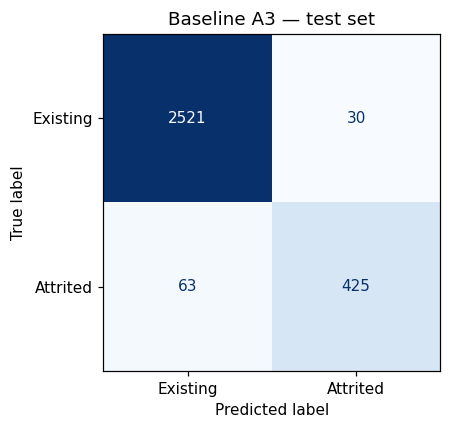

                   precision    recall  f1-score   support

Existing Customer     0.9756    0.9882    0.9819      2551
Attrited Customer     0.9341    0.8709    0.9014       488

         accuracy                         0.9694      3039
        macro avg     0.9548    0.9296    0.9416      3039
     weighted avg     0.9689    0.9694    0.9690      3039



In [ ]:
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, baseline_test_pred, display_labels=["Existing", "Attrited"],
    cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Baseline A3 — test set")
plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/01_confusion_matrix_baseline.png", bbox_inches="tight", dpi=200)
plt.show()

print(classification_report(y_test, baseline_test_pred, digits=4,
                            target_names=["Existing Customer", "Attrited Customer"]))

## 1.6 Ringkasan baseline

In [ ]:
experiment_table = pd.DataFrame([{
    "Experiment": "D0",
    "Dataset": "Assignment #3 baseline data",
    "CV Macro F1": f"{d0_summary['Macro F1 mean'].iloc[0]:.4f} ± {d0_summary['Macro F1 std'].iloc[0]:.4f}",
    "CV F1 (churn)": f"{d0_summary['F1 (churn) mean'].iloc[0]:.4f} ± {d0_summary['F1 (churn) std'].iloc[0]:.4f}",
    "CV Recall (churn)": f"{d0_summary['Recall (churn) mean'].iloc[0]:.4f} ± {d0_summary['Recall (churn) std'].iloc[0]:.4f}",
    "CV PR-AUC": f"{d0_summary['PR-AUC mean'].iloc[0]:.4f} ± {d0_summary['PR-AUC std'].iloc[0]:.4f}",
}]).set_index("Experiment")
experiment_table.to_csv(f"{OUTPUT_DIR}/a4_experiment_table.csv")

with open(f"{OUTPUT_DIR}/a4_baseline.json", "w") as f:
    json.dump({"hyperparameters": A3_FINAL_HYPERPARAMETERS,
               "cv_summary": d0_summary.iloc[0].round(6).to_dict(),
               "test_metrics": {k: round(v, 6) for k, v in baseline_test_metrics.items()}},
              f, indent=2)
experiment_table

,Dataset,CV Macro F1,CV F1 (churn),CV Recall (churn),CV PR-AUC
Experiment,,,,,
D0,Assignment #3 baseline data,0.9464 ± 0.0069,0.9096 ± 0.0119,0.8894 ± 0.0226,0.9723 ± 0.0068


# 2. Identify Data-Quality Problems

In [ ]:
train_frame = X_train.assign(churn=y_train)
overall_churn_rate = y_train.mean()

def churn_profile(mask, label):
    return {"Kondisi": label, "n": int(mask.sum()), "% training": mask.mean() * 100,
            "Churn rate": y_train[mask].mean() if mask.any() else np.nan}

print(f"Churn rate training keseluruhan: {overall_churn_rate:.4f}")

Churn rate training keseluruhan: 0.1607


## 2.1 Class imbalance

In [ ]:
class_distribution = pd.DataFrame({
    "n": y_train.value_counts().sort_index(),
    "proporsi": y_train.value_counts(normalize=True).sort_index().round(4),
}).rename(index={0: "Existing Customer", 1: "Attrited Customer"})
print(f"Rasio mayoritas : minoritas = {class_distribution['n'].iloc[0] / class_distribution['n'].iloc[1]:.2f} : 1")
class_distribution

Rasio mayoritas : minoritas = 5.22 : 1


,n,proporsi
churn,,
Existing Customer,5949,0.8393
Attrited Customer,1139,0.1607


## 2.2 Duplikat dan near-duplicate

In [ ]:
from sklearn.neighbors import NearestNeighbors

feature_columns = [c for c in raw_dataset.columns
                   if c not in IDENTIFIER_COLUMNS + [TARGET_COLUMN] and not c.startswith(LEAKAGE_PREFIX)]
full_features = raw_dataset[feature_columns]

# Ruang fitur model (encoding + scaling dari training set) untuk jarak tetangga terdekat
encoder_scaler = make_pipeline()[:-1].fit(X_train, y_train)
Z_train = encoder_scaler.transform(X_train).to_numpy()
Z_test  = encoder_scaler.transform(X_test).to_numpy()

nn_train = NearestNeighbors(n_neighbors=2).fit(Z_train)
dist_train, idx_train = nn_train.kneighbors(Z_train)
nearest_dist = dist_train[:, 1]
label_conflict = y_train.to_numpy() != y_train.to_numpy()[idx_train[:, 1]]
dist_test_to_train = nn_train.kneighbors(Z_test, n_neighbors=1)[0][:, 0]

duplicate_checks = pd.DataFrame([
    ("Baris identik (tanpa CLIENTNUM), seluruh data",          int(raw_dataset.drop(columns=IDENTIFIER_COLUMNS).duplicated().sum())),
    ("CLIENTNUM ganda",                                         int(raw_dataset["CLIENTNUM"].duplicated().sum())),
    ("Vektor fitur identik, seluruh data",                      int(full_features.duplicated().sum())),
    ("Vektor fitur identik dengan label berbeda",               int(raw_dataset.groupby(feature_columns, dropna=False)
                                                                    [TARGET_COLUMN].nunique().gt(1).sum())),
    ("Pasangan training berjarak < 0,5 (ruang fitur ter-skala)", int((nearest_dist < 0.5).sum())),
    ("  ... di antaranya berlabel berbeda",                     int(((nearest_dist < 0.5) & label_conflict).sum())),
    ("Baris test berjarak < 0,5 dari baris training",           int((dist_test_to_train < 0.5).sum())),
], columns=["Pemeriksaan", "Jumlah"]).set_index("Pemeriksaan")
display(duplicate_checks)

print(f"Jarak tetangga terdekat training : min {nearest_dist.min():.3f} | persentil 1% {np.quantile(nearest_dist, .01):.3f} | median {np.median(nearest_dist):.3f}")
print(f"Jarak test -> training           : min {dist_test_to_train.min():.3f} | persentil 1% {np.quantile(dist_test_to_train, .01):.3f}")

,Jumlah
Pemeriksaan,
"Baris identik (tanpa CLIENTNUM), seluruh data",0
CLIENTNUM ganda,0
"Vektor fitur identik, seluruh data",0
Vektor fitur identik dengan label berbeda,0
"Pasangan training berjarak < 0,5 (ruang fitur ter-skala)",0
... di antaranya berlabel berbeda,0
"Baris test berjarak < 0,5 dari baris training",0


Jarak tetangga terdekat training : min 0.543 | persentil 1% 1.210 | median 2.083
Jarak test -> training           : min 0.782 | persentil 1% 1.259


## 2.3 Nilai tidak konsisten

In [ ]:
d = X_train
computed_utilization = d["Total_Revolving_Bal"] / d["Credit_Limit"]
consistency_rules = pd.DataFrame([
    ("Avg_Utilization_Ratio = Total_Revolving_Bal / Credit_Limit (selisih > 0,001)",
     int(((computed_utilization - d["Avg_Utilization_Ratio"]).abs() > 0.001).sum())),
    ("Avg_Open_To_Buy = Credit_Limit - Total_Revolving_Bal (selisih > 1)",
     int(((d["Credit_Limit"] - d["Total_Revolving_Bal"] - d["Avg_Open_To_Buy"]).abs() > 1).sum())),
    ("Total_Revolving_Bal > Credit_Limit",                int((d["Total_Revolving_Bal"] > d["Credit_Limit"]).sum())),
    ("Avg_Utilization_Ratio di luar [0, 1]",              int((~d["Avg_Utilization_Ratio"].between(0, 1)).sum())),
    ("Usia saat akun dibuka < 18 tahun",                  int(((d["Customer_Age"] - d["Months_on_book"] / 12) < 18).sum())),
    ("Months_Inactive_12_mon / Contacts_Count_12_mon > 12", int(((d["Months_Inactive_12_mon"] > 12) | (d["Contacts_Count_12_mon"] > 12)).sum())),
    ("Total_Relationship_Count < 1",                      int((d["Total_Relationship_Count"] < 1).sum())),
    ("Total_Trans_Ct <= 0 atau Total_Trans_Amt <= 0",     int(((d["Total_Trans_Ct"] <= 0) | (d["Total_Trans_Amt"] <= 0)).sum())),
    ("Nilai kategorik di luar kamus encoding",
     int((~d["Education_Level"].isin(EDUCATION_ORDER)).sum() + (~d["Income_Category"].isin(INCOME_ORDER)).sum()
         + (~d["Card_Category"].isin(CARD_ORDER)).sum() + (~d["Gender"].isin(GENDER_MAP)).sum())),
    ("Nilai kosong (NaN)",                                int(d.isna().sum().sum())),
], columns=["Aturan konsistensi", "Pelanggaran (training)"]).set_index("Aturan konsistensi")
consistency_rules

,Pelanggaran (training)
Aturan konsistensi,
"Avg_Utilization_Ratio = Total_Revolving_Bal / Credit_Limit (selisih > 0,001)",0
Avg_Open_To_Buy = Credit_Limit - Total_Revolving_Bal (selisih > 1),0
Total_Revolving_Bal > Credit_Limit,0
"Avg_Utilization_Ratio di luar [0, 1]",0
Usia saat akun dibuka < 18 tahun,0
Months_Inactive_12_mon / Contacts_Count_12_mon > 12,0
Total_Relationship_Count < 1,0
Total_Trans_Ct <= 0 atau Total_Trans_Amt <= 0,0
Nilai kategorik di luar kamus encoding,0


In [ ]:
categorical_domains = pd.DataFrame({c: [", ".join(sorted(raw_dataset[c].unique()))]
                                    for c in ["Gender", "Education_Level", "Marital_Status",
                                              "Income_Category", "Card_Category", TARGET_COLUMN]}).T
categorical_domains.columns = ["Nilai unik (seluruh data)"]
categorical_domains

,Nilai unik (seluruh data)
Gender,"F, M"
Education_Level,"College, Doctorate, Graduate, High School, Pos..."
Marital_Status,"Divorced, Married, Single, Unknown"
Income_Category,"$120K +, $40K - $60K, $60K - $80K, $80K - $120..."
Card_Category,"Blue, Gold, Platinum, Silver"
Attrition_Flag,"Attrited Customer, Existing Customer"


## 2.4 Nilai anomali dan nilai batas

In [ ]:
credit_floor, credit_cap = d["Credit_Limit"].min(), d["Credit_Limit"].max()
revolving_cap = d["Total_Revolving_Bal"].max()
mob_counts = d["Months_on_book"].value_counts().sort_index()
mob_neighbours = mob_counts.drop(36).loc[30:42]

anomaly_table = pd.DataFrame([
    churn_profile(d["Months_on_book"] == 36,              "Months_on_book = 36 (lonjakan)"),
    churn_profile(d["Credit_Limit"] == credit_floor,      f"Credit_Limit = batas bawah ({credit_floor:,.1f})"),
    churn_profile(d["Credit_Limit"] == credit_cap,        f"Credit_Limit = batas atas ({credit_cap:,.0f})"),
    churn_profile(d["Total_Revolving_Bal"] == revolving_cap, f"Total_Revolving_Bal = batas atas ({revolving_cap:,.0f})"),
    churn_profile(d["Total_Revolving_Bal"] == 0,          "Total_Revolving_Bal = 0"),
    churn_profile(d["Total_Amt_Chng_Q4_Q1"] > 3,          "Total_Amt_Chng_Q4_Q1 > 3"),
    churn_profile(d["Total_Ct_Chng_Q4_Q1"] > 3,           "Total_Ct_Chng_Q4_Q1 > 3"),
    churn_profile(d["Total_Ct_Chng_Q4_Q1"] == 0,          "Total_Ct_Chng_Q4_Q1 = 0"),
]).set_index("Kondisi")

print(f"Months_on_book = 36 : {mob_counts.loc[36]} baris, "
      f"{mob_counts.loc[36] / mob_neighbours.mean():.1f}x rata-rata nilai sekitarnya (30-42 bulan, {mob_neighbours.mean():.0f} baris)")
anomaly_table.round(4)

Months_on_book = 36 : 1728 baris, 7.7x rata-rata nilai sekitarnya (30-42 bulan, 224 baris)


,n,% training,Churn rate
Kondisi,,,
Months_on_book = 36 (lonjakan),1728,24.3792,0.1765
"Credit_Limit = batas bawah (1,438.3)",341,4.8109,0.2639
"Credit_Limit = batas atas (34,516)",359,5.0649,0.1894
"Total_Revolving_Bal = batas atas (2,517)",348,4.9097,0.3218
Total_Revolving_Bal = 0,1723,24.3087,0.3645
Total_Amt_Chng_Q4_Q1 > 3,2,0.0282,0.0000
Total_Ct_Chng_Q4_Q1 > 3,2,0.0282,0.0000
Total_Ct_Chng_Q4_Q1 = 0,2,0.0282,1.0000


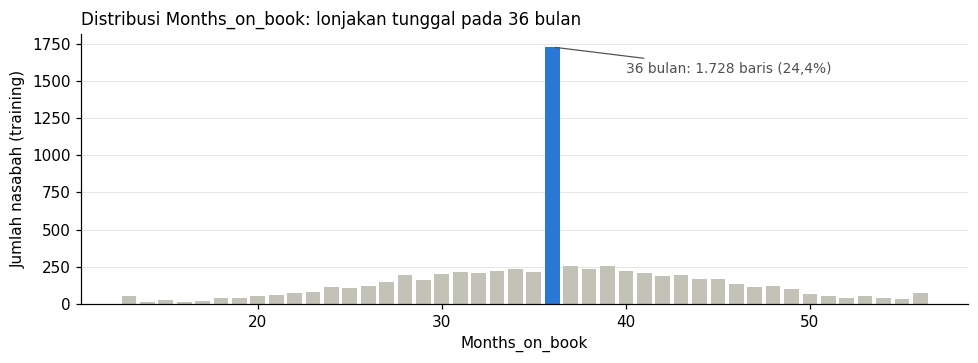

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bar_colors = ["#2a78d6" if v == 36 else "#c3c2b7" for v in mob_counts.index]
ax.bar(mob_counts.index, mob_counts.values, width=0.8, color=bar_colors)
spike_label = f"36 bulan: {mob_counts.loc[36]:,} baris ({mob_counts.loc[36] / len(d):.1%})"
ax.annotate(spike_label.replace(",", "_").replace(".", ",").replace("_", "."),
            xy=(36, mob_counts.loc[36]), xytext=(40, mob_counts.loc[36] * 0.9),
            color="#52514e", fontsize=9, arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.8))
ax.set_xlabel("Months_on_book")
ax.set_ylabel("Jumlah nasabah (training)")
ax.set_title("Distribusi Months_on_book: lonjakan tunggal pada 36 bulan", loc="left", fontsize=11)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(axis="y", color="#e5e4df", lw=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/02_months_on_book_spike.png", bbox_inches="tight", dpi=200)
plt.show()

## 2.5 Segmen bermasalah: error baseline per segmen (prediksi out-of-fold)

In [ ]:
baseline_oof_proba = out_of_fold_proba(baseline_pipeline, X_train, y_train)
baseline_oof_pred = (baseline_oof_proba >= 0.5).astype(int)
pd.DataFrame({"churn": y_train, "oof_proba": baseline_oof_proba, "oof_pred": baseline_oof_pred,
              "fold": cv_folds}).to_csv(f"{OUTPUT_DIR}/a4_baseline_oof_predictions.csv")

def wilson_interval(errors, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = errors / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

any_unknown = (d[["Education_Level", "Marital_Status", "Income_Category"]] == "Unknown").any(axis=1)

# Anomali multivariat: Isolation Forest pada ruang fitur model (Z_train, Langkah 2.2); 1% skor tertinggi
from sklearn.ensemble import IsolationForest
iso_forest = IsolationForest(n_estimators=300, random_state=RANDOM_SEED).fit(Z_train)
anomaly_score = pd.Series(-iso_forest.score_samples(Z_train), index=d.index)
multivariate_anomaly = anomaly_score >= anomaly_score.quantile(0.99)

segments = {
    "Seluruh training":                     pd.Series(True, index=d.index),
    "Unknown pada >= 1 kolom":              any_unknown,
    "Education_Level = Unknown":            d["Education_Level"] == "Unknown",
    "Income_Category = Unknown":            d["Income_Category"] == "Unknown",
    "Marital_Status = Unknown":             d["Marital_Status"] == "Unknown",
    "Card_Category = Gold":                 d["Card_Category"] == "Gold",
    "Card_Category = Platinum":             d["Card_Category"] == "Platinum",
    "Credit_Limit = batas bawah":           d["Credit_Limit"] == credit_floor,
    "Credit_Limit = batas atas":            d["Credit_Limit"] == credit_cap,
    "Total_Revolving_Bal = 0":              d["Total_Revolving_Bal"] == 0,
    "Total_Revolving_Bal = batas atas":     d["Total_Revolving_Bal"] == revolving_cap,
    "Months_on_book = 36":                  d["Months_on_book"] == 36,
    "Anomali multivariat (1% teratas)":     multivariate_anomaly,
}

oof_error = baseline_oof_pred != y_train
segment_rows = []
for name, mask in segments.items():
    n, errors = int(mask.sum()), int(oof_error[mask].sum())
    low, high = wilson_interval(errors, n)
    segment_rows.append({
        "Segmen": name, "n": n, "Churn rate": y_train[mask].mean(),
        "Error rate OOF": errors / n, "CI 95% bawah": low, "CI 95% atas": high,
        "FN": int((mask & (y_train == 1) & (baseline_oof_pred == 0)).sum()),
        "FP": int((mask & (y_train == 0) & (baseline_oof_pred == 1)).sum()),
    })
segment_errors = pd.DataFrame(segment_rows).set_index("Segmen")
overall_error = segment_errors.loc["Seluruh training", "Error rate OOF"]
segment_errors["Di atas rata-rata (CI)"] = segment_errors["CI 95% bawah"] > overall_error
segment_errors.to_csv(f"{OUTPUT_DIR}/a4_segment_errors.csv")
segment_errors.round(4)

,n,Churn rate,Error rate OOF,CI 95% bawah,CI 95% atas,FN,FP,Di atas rata-rata (CI)
Segmen,,,,,,,,
Seluruh training,7088,0.1607,0.0284,0.0247,0.0325,126,75,False
Unknown pada >= 1 kolom,2130,0.1732,0.0244,0.0187,0.0319,30,22,False
Education_Level = Unknown,1064,0.1711,0.0216,0.0144,0.0322,15,8,False
Income_Category = Unknown,761,0.1721,0.0197,0.0120,0.0323,8,7,False
Marital_Status = Unknown,534,0.1854,0.0262,0.0157,0.0435,7,7,False
Card_Category = Gold,85,0.2118,0.0235,0.0065,0.0818,2,0,False
Card_Category = Platinum,14,0.2143,0.0714,0.0127,0.3147,1,0,False
Credit_Limit = batas bawah,341,0.2639,0.0323,0.0181,0.0568,5,6,False
Credit_Limit = batas atas,359,0.1894,0.0446,0.0276,0.0712,9,7,False


In [ ]:
# Profil anomali multivariat dibanding seluruh training
profile_cols = ["Credit_Limit", "Total_Trans_Amt", "Total_Trans_Ct", "Total_Revolving_Bal", "Customer_Age"]
anomaly_profile = pd.DataFrame({"Anomali (1% teratas), median": d.loc[multivariate_anomaly, profile_cols].median(),
                                "Seluruh training, median": d[profile_cols].median()})
display(anomaly_profile)
pd.DataFrame({"Anomali (1% teratas)": d.loc[multivariate_anomaly, "Card_Category"].value_counts(),
              "Seluruh training": d["Card_Category"].value_counts()})

,"Anomali (1% teratas), median","Seluruh training, median"
Credit_Limit,34516.0,4515.0
Total_Trans_Amt,9177.0,3906.0
Total_Trans_Ct,98.0,67.0
Total_Revolving_Bal,1428.0,1283.0
Customer_Age,45.0,46.0


,Anomali (1% teratas),Seluruh training
Card_Category,,
Blue,13,6604
Gold,26,85
Platinum,8,14
Silver,24,385


## 2.6 Ringkasan masalah kualitas data

In [ ]:
def num(x, digits=1):
    return f"{x:,.{digits}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def pct(x):
    return num(x * 100) + "%"

seg = segment_errors
overall_error = seg.loc["Seluruh training", "Error rate OOF"]

def segment_evidence(name):
    row = seg.loc[name]
    return (f"n={int(row['n']):,}".replace(",", ".") + f", error OOF {pct(row['Error rate OOF'])} "
            f"(CI 95% {pct(row['CI 95% bawah'])}-{pct(row['CI 95% atas'])}) vs {pct(overall_error)} keseluruhan")

def segment_decision(name, if_high, if_normal):
    return if_high if seg.loc[name, "Di atas rata-rata (CI)"] else if_normal

n_major, n_minor = class_distribution["n"].iloc[0], class_distribution["n"].iloc[1]
mob36 = anomaly_table.loc["Months_on_book = 36 (lonjakan)"]

data_quality_summary = pd.DataFrame([
    ("Class imbalance",
     f"{n_major:,} : {n_minor:,}".replace(",", ".") + f" ({num(n_major / n_minor, 2)} : 1)",
     "A3: hanya SMOTEENN diuji, ditolak",
     "Terbuka: Langkah 3 (class weighting dan SMOTE)"),
    ("Label salah / mencurigakan",
     "Tidak ada sumber label kedua, sehingga tidak dapat diperiksa dengan aturan",
     "Belum pernah diperiksa",
     "Terbuka: Langkah 4 (cleanlab)"),
    ("Duplikat / near-duplicate",
     f"0 baris identik; jarak tetangga terdekat minimum {num(nearest_dist.min(), 2)}; "
     f"{int((dist_test_to_train < 0.5).sum())} baris test berdekatan dengan training",
     "Belum diperiksa eksplisit",
     "Tidak ditemukan masalah"),
    ("Nilai tidak konsisten",
     f"{int(consistency_rules.iloc[:, 0].sum())} pelanggaran dari {len(consistency_rules)} aturan; domain kategorik bersih",
     "Redundansi Avg_Open_To_Buy ditangani di A3 (H3)",
     "Tidak ditemukan masalah"),
    ("Anomali: lonjakan Months_on_book = 36",
     f"{int(mob36['n']):,}".replace(",", ".") + f" baris ({num(mob36['% training'])}%), "
     f"{num(mob_counts.loc[36] / mob_neighbours.mean())}x nilai sekitarnya; " + segment_evidence("Months_on_book = 36"),
     "Belum teridentifikasi",
     segment_decision("Months_on_book = 36",
                      "Bukti baru: dugaan nilai pengganti; kandidat koreksi kualitas data (D2)",
                      "Bukti baru: dugaan nilai pengganti; error tidak meningkat, kandidat koreksi D2 opsional")),
    ("Anomali: nilai batas Credit_Limit",
     f"batas bawah n={int(seg.loc['Credit_Limit = batas bawah', 'n'])}, batas atas n={int(seg.loc['Credit_Limit = batas atas', 'n'])}; "
     f"error OOF {pct(seg.loc['Credit_Limit = batas bawah', 'Error rate OOF'])} dan {pct(seg.loc['Credit_Limit = batas atas', 'Error rate OOF'])}",
     "A3: outlier dipertahankan (H5)",
     segment_decision("Credit_Limit = batas atas",
                      "Nilai terpotong dan error meningkat: dianalisis di Langkah 7",
                      "Nilai valid (batas kebijakan); dicatat sebagai keterbatasan")),
    ("Anomali multivariat (Isolation Forest)",
     segment_evidence("Anomali multivariat (1% teratas)"),
     "A3: outlier univariat (IQR) dipertahankan (H5); multivariat belum diperiksa",
     segment_decision("Anomali multivariat (1% teratas)",
                      "Bukti baru: error meningkat; dianalisis di Langkah 7",
                      "Profil nasabah premium (limit tinggi, Gold/Platinum); error tidak meningkat, tidak ditindaklanjuti")),
    ("Anomali: Total_Revolving_Bal terpotong di batas atas",
     segment_evidence("Total_Revolving_Bal = batas atas"),
     "Belum teridentifikasi",
     segment_decision("Total_Revolving_Bal = batas atas",
                      "Bukti baru: nilai terpotong (tidak dapat dipulihkan), error meningkat; dianalisis di Langkah 7",
                      "Nilai terpotong; dicatat sebagai keterbatasan")),
    ("Target tidak reliabel",
     "Attrition_Flag hanya berisi 2 nilai valid; kolom Naive_Bayes_* adalah skor model lain",
     "A2: kolom Naive_Bayes_* dibuang (kebocoran)",
     "Diperiksa bersama label di Langkah 4"),
    ("Segmen: Total_Revolving_Bal = 0",
     segment_evidence("Total_Revolving_Bal = 0"),
     "Belum dibahas",
     segment_decision("Total_Revolving_Bal = 0",
                      "Bukti baru: error di atas rata-rata; pola valid, dianalisis di Langkah 7",
                      "Tidak ditemukan masalah")),
    ("Segmen: kategori Unknown",
     segment_evidence("Unknown pada >= 1 kolom"),
     "A3: dipertahankan sebagai kategori (H2)",
     segment_decision("Unknown pada >= 1 kolom",
                      "Bukti baru: error meningkat; diinvestigasi ulang",
                      "Tidak diinvestigasi ulang (tidak ada bukti baru)")),
    ("Segmen: kategori kartu langka",
     f"Gold n={int(seg.loc['Card_Category = Gold', 'n'])}, Platinum n={int(seg.loc['Card_Category = Platinum', 'n'])}",
     "Belum dibahas",
     "Terlalu kecil untuk dievaluasi; dicatat sebagai keterbatasan"),
], columns=["Masalah", "Bukti", "Status A2/A3", "Tindak lanjut A4"]).set_index("Masalah")
data_quality_summary.to_csv(f"{OUTPUT_DIR}/a4_data_quality_summary.csv")

with pd.option_context("display.max_colwidth", None):
    display(data_quality_summary)

,Bukti,Status A2/A3,Tindak lanjut A4
Masalah,,,
Class imbalance,"5.949 : 1.139 (5,22 : 1)","A3: hanya SMOTEENN diuji, ditolak",Terbuka: Langkah 3 (class weighting dan SMOTE)
Label salah / mencurigakan,"Tidak ada sumber label kedua, sehingga tidak dapat diperiksa dengan aturan",Belum pernah diperiksa,Terbuka: Langkah 4 (cleanlab)
Duplikat / near-duplicate,"0 baris identik; jarak tetangga terdekat minimum 0,54; 0 baris test berdekatan dengan training",Belum diperiksa eksplisit,Tidak ditemukan masalah
Nilai tidak konsisten,0 pelanggaran dari 10 aturan; domain kategorik bersih,Redundansi Avg_Open_To_Buy ditangani di A3 (H3),Tidak ditemukan masalah
Anomali: lonjakan Months_on_book = 36,"1.728 baris (24,4%), 7,7x nilai sekitarnya; n=1.728, error OOF 2,8% (CI 95% 2,2%-3,7%) vs 2,8% keseluruhan",Belum teridentifikasi,"Bukti baru: dugaan nilai pengganti; error tidak meningkat, kandidat koreksi D2 opsional"
Anomali: nilai batas Credit_Limit,"batas bawah n=341, batas atas n=359; error OOF 3,2% dan 4,5%",A3: outlier dipertahankan (H5),Nilai valid (batas kebijakan); dicatat sebagai keterbatasan
Anomali multivariat (Isolation Forest),"n=71, error OOF 2,8% (CI 95% 0,8%-9,7%) vs 2,8% keseluruhan",A3: outlier univariat (IQR) dipertahankan (H5); multivariat belum diperiksa,"Profil nasabah premium (limit tinggi, Gold/Platinum); error tidak meningkat, tidak ditindaklanjuti"
Anomali: Total_Revolving_Bal terpotong di batas atas,"n=348, error OOF 6,0% (CI 95% 4,0%-9,0%) vs 2,8% keseluruhan",Belum teridentifikasi,"Bukti baru: nilai terpotong (tidak dapat dipulihkan), error meningkat; dianalisis di Langkah 7"
Target tidak reliabel,Attrition_Flag hanya berisi 2 nilai valid; kolom Naive_Bayes_* adalah skor model lain,A2: kolom Naive_Bayes_* dibuang (kebocoran),Diperiksa bersama label di Langkah 4


# 3. Address Class Imbalance

## 3.1 Kandidat intervensi: class weighting dan SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE, SMOTENC

class_counts = y_train.value_counts()
imbalance_ratio = class_counts[0] / class_counts[1]          # 5.949 / 1.139 = 5,22
print(f"Training: {class_counts[0]} non-churn : {class_counts[1]} churn  ->  rasio {imbalance_ratio:.2f} : 1")
print("scale_pos_weight untuk D1a =", round(imbalance_ratio, 4),
      "(bobot kelas churn = rasio mayoritas : minoritas, sehingga total bobot kedua kelas setara)")

D0_LABEL = d0_folds["Eksperimen"].iloc[0]
IMBALANCE_CANDIDATES = {
    "D1a Class Weighting": make_pipeline(extra_model_params={"scale_pos_weight": imbalance_ratio}),
    "D1b SMOTE":           make_pipeline(sampler=SMOTE(random_state=RANDOM_SEED, k_neighbors=5)),
}

Training: 5949 non-churn : 1139 churn  ->  rasio 5.22 : 1
scale_pos_weight untuk D1a = 5.223 (bobot kelas churn = rasio mayoritas : minoritas, sehingga total bobot kedua kelas setara)


## 3.2 Pemeriksaan SMOTE standar pada kolom biner, ordinal, dan one-hot

In [ ]:
encode_scale = make_pipeline()[:-1]                      # A3Encoder + StandardScaler
train_idx, _ = next(iter(get_cv().split(X_train, y_train)))
X_fold, y_fold = X_train.iloc[train_idx], y_train.iloc[train_idx]
Z_fold = encode_scale.fit(X_fold, y_fold).transform(X_fold)
scaler_fold = encode_scale.named_steps["scale"]

Z_res, y_res = SMOTE(random_state=RANDOM_SEED, k_neighbors=5).fit_resample(Z_fold, y_fold)
synthetic = pd.DataFrame(scaler_fold.inverse_transform(Z_res.iloc[len(Z_fold):]), columns=Z_fold.columns)
original  = pd.DataFrame(scaler_fold.inverse_transform(Z_fold), columns=Z_fold.columns)

DISCRETE_COLUMNS = (["Gender", "Education_Level", "Income_Category", "Card_Category"]
                    + [c for c in Z_fold.columns if c.startswith("Marital_")]
                    + ["Dependent_count", "Total_Relationship_Count", "Months_Inactive_12_mon", "Contacts_Count_12_mon"])

def invalid_share(column):
    allowed = np.sort(original[column].unique())
    gap = np.abs(synthetic[column].to_numpy()[:, None] - allowed[None, :]).min(axis=1)
    return float((gap > 1e-6).mean())

smote_check = pd.DataFrame({
    "Nilai unik asli (training fold)":  [original[c].nunique() for c in DISCRETE_COLUMNS],
    "Nilai unik sintetis":              [synthetic[c].nunique() for c in DISCRETE_COLUMNS],
    "Sintetis di luar nilai asli":      [invalid_share(c) for c in DISCRETE_COLUMNS],
}, index=DISCRETE_COLUMNS)
display(smote_check.round(4))

print(f"Jumlah baris sintetis pada fold 1: {len(synthetic)} (training fold: {len(Z_fold)} baris)")
FRACTION_FOUND = bool((smote_check["Sintetis di luar nilai asli"] > 0).any())
print("SMOTE standar menghasilkan nilai di luar domain kolom diskret:", FRACTION_FOUND)
smote_check.to_csv(f"{OUTPUT_DIR}/a4_s3_smote_discrete_check.csv")

if FRACTION_FOUND:
    # SMOTENC: kolom kategorik diisi dengan nilai modus tetangga, bukan interpolasi
    categorical_names = ["Gender", "Education_Level", "Income_Category", "Card_Category"] \
                        + [c for c in Z_fold.columns if c.startswith("Marital_")]
    categorical_positions = [list(Z_fold.columns).index(c) for c in categorical_names]
    IMBALANCE_CANDIDATES["D1c SMOTENC"] = make_pipeline(
        sampler=SMOTENC(categorical_features=categorical_positions, random_state=RANDOM_SEED, k_neighbors=5))
    print("D1c SMOTENC ditambahkan sebagai kandidat (kolom kategorik:", categorical_names, ")")
else:
    print("Tidak ada nilai di luar domain; SMOTE standar dipakai tanpa varian kategorik.")

,Nilai unik asli (training fold),Nilai unik sintetis,Sintetis di luar nilai asli
Gender,2,235,0.0606
Education_Level,7,2620,0.6791
Income_Category,6,2066,0.5353
Card_Category,4,112,0.0281
Marital_Divorced,2,4,0.0005
Marital_Married,2,57,0.0143
Marital_Single,2,53,0.0133
Marital_Unknown,2,18,0.0042
Dependent_count,6,2540,0.6585
Total_Relationship_Count,6,2698,0.6996


Jumlah baris sintetis pada fold 1: 3848 (training fold: 5670 baris)
SMOTE standar menghasilkan nilai di luar domain kolom diskret: True
D1c SMOTENC ditambahkan sebagai kandidat (kolom kategorik: ['Gender', 'Education_Level', 'Income_Category', 'Card_Category', 'Marital_Divorced', 'Marital_Married', 'Marital_Single', 'Marital_Unknown'] )


## 3.3 Cross-validation D0 dan kandidat

In [ ]:
d1_folds = pd.concat([cross_validate_pipeline(pipe, X_train, y_train, label=name)
                      for name, pipe in IMBALANCE_CANDIDATES.items()], ignore_index=True)
comparison_folds = pd.concat([d0_folds, d1_folds], ignore_index=True)
comparison_folds.to_csv(f"{OUTPUT_DIR}/a4_s3_cv_folds.csv", index=False)

d1_summary = format_mean_std(comparison_folds)
d1_summary.to_csv(f"{OUTPUT_DIR}/a4_s3_cv_summary.csv")
display(d1_summary.T)
print("Fold per eksperimen:", comparison_folds.groupby("Eksperimen", sort=False)["Fold"].nunique().to_dict())

Eksperimen,D0 Assignment #3 baseline data,D1a Class Weighting,D1b SMOTE,D1c SMOTENC
Macro F1,0.9464 ± 0.0069,0.9463 ± 0.0046,0.9478 ± 0.0046,0.9474 ± 0.0058
F1 (churn),0.9096 ± 0.0119,0.9103 ± 0.0079,0.9122 ± 0.0080,0.9117 ± 0.0100
Precision (churn),0.9311 ± 0.0022,0.8903 ± 0.0083,0.9202 ± 0.0125,0.9110 ± 0.0090
Recall (churn),0.8894 ± 0.0226,0.9315 ± 0.0197,0.9052 ± 0.0255,0.9131 ± 0.0257
PR-AUC,0.9723 ± 0.0068,0.9715 ± 0.0072,0.9720 ± 0.0057,0.9708 ± 0.0060
ROC-AUC,0.9935 ± 0.0022,0.9931 ± 0.0021,0.9934 ± 0.0019,0.9931 ± 0.0023
Balanced Accuracy,0.9384 ± 0.0111,0.9547 ± 0.0091,0.9450 ± 0.0114,0.9480 ± 0.0119
Accuracy,0.9716 ± 0.0034,0.9705 ± 0.0023,0.9721 ± 0.0020,0.9716 ± 0.0027


Fold per eksperimen: {'D0 Assignment #3 baseline data': 5, 'D1a Class Weighting': 5, 'D1b SMOTE': 5, 'D1c SMOTENC': 5}


## 3.4 Selisih Macro F1 per fold dan pemilihan D1

In [ ]:
baseline_macro = d0_folds.set_index("Fold")["Macro F1"]
fold_comparison = d1_folds.pivot(index="Fold", columns="Eksperimen", values="Macro F1")[list(IMBALANCE_CANDIDATES)]
fold_diff = fold_comparison.sub(baseline_macro, axis=0).add_suffix(" - D0")
fold_table = pd.concat([baseline_macro.rename("D0"), fold_comparison, fold_diff], axis=1)
display(fold_table.round(4))
fold_table.to_csv(f"{OUTPUT_DIR}/a4_s3_macro_f1_by_fold.csv")

# Aturan (ditetapkan sebelum melihat hasil, dipakai juga di Langkah 5):
# D1 = kandidat dengan mean Macro F1 tertinggi; D1 memperbaiki D0 hanya bila mean-nya lebih tinggi
# DAN unggul di minimal 4 dari 5 fold
candidate_means = d1_folds.groupby("Eksperimen")["Macro F1"].mean()
SELECTED_D1 = candidate_means.idxmax()
folds_won = int((fold_comparison[SELECTED_D1] > baseline_macro).sum())
D1_IMPROVES = bool(candidate_means[SELECTED_D1] > d0_folds["Macro F1"].mean() and folds_won >= 4)

print(f"D0 mean Macro F1 : {d0_folds['Macro F1'].mean():.4f}")
print(f"Kandidat terbaik : {SELECTED_D1} ({candidate_means[SELECTED_D1]:.4f}), unggul di {folds_won} dari {N_CV_SPLITS} fold")
print(f"D1_IMPROVES      : {D1_IMPROVES}"
      + ("" if D1_IMPROVES else "  -> selisih tidak konsisten antar-fold: dilaporkan sebagai tidak berbeda bermakna"))

,D0,D1a Class Weighting,D1b SMOTE,D1c SMOTENC,D1a Class Weighting - D0,D1b SMOTE - D0,D1c SMOTENC - D0
Fold,,,,,,,
1,0.9482,0.9495,0.9476,0.9471,0.0013,-0.0007,-0.0011
2,0.9567,0.9515,0.9536,0.9538,-0.0051,-0.0030,-0.0029
3,0.9350,0.9387,0.9404,0.9371,0.0037,0.0054,0.0022
4,0.9468,0.9435,0.9461,0.9472,-0.0033,-0.0006,0.0004
5,0.9454,0.9483,0.9514,0.9519,0.0029,0.0060,0.0066


D0 mean Macro F1 : 0.9464
Kandidat terbaik : D1b SMOTE (0.9478), unggul di 2 dari 5 fold
D1_IMPROVES      : False  -> selisih tidak konsisten antar-fold: dilaporkan sebagai tidak berbeda bermakna


## 3.5 Trade-off precision-recall dan visualisasi

,Macro F1,Precision (churn),Recall (churn),PR-AUC,ROC-AUC,Δ Recall vs D0,Δ Precision vs D0
Eksperimen,,,,,,,
D0 Assignment #3 baseline data,0.9464,0.9311,0.8894,0.9723,0.9935,0.0000,0.0000
D1a Class Weighting,0.9463,0.8903,0.9315,0.9715,0.9931,0.0421,-0.0408
D1b SMOTE,0.9478,0.9202,0.9052,0.9720,0.9934,0.0158,-0.0109
D1c SMOTENC,0.9474,0.9110,0.9131,0.9708,0.9931,0.0237,-0.0201


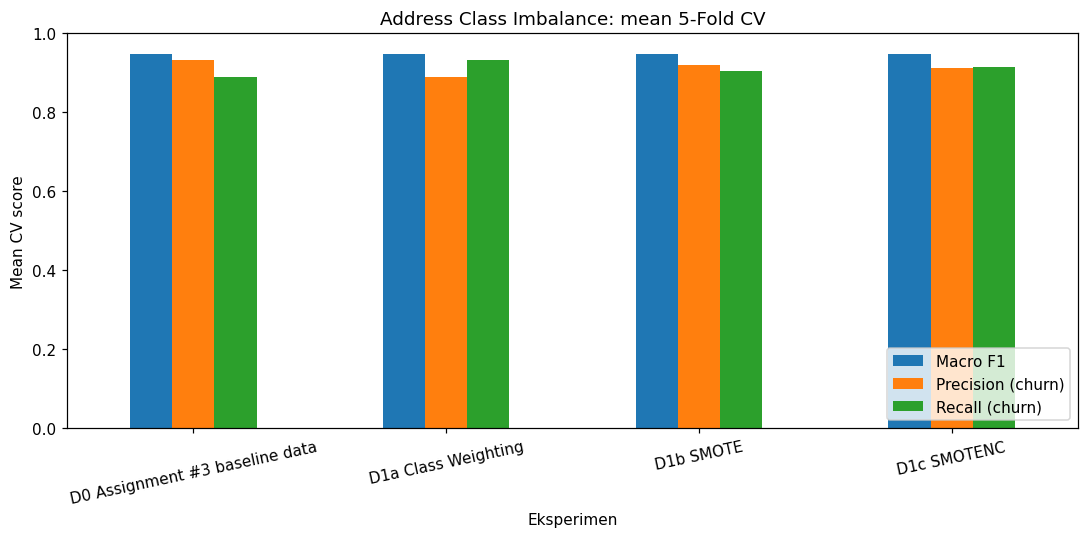

In [ ]:
trade_off = (comparison_folds.groupby("Eksperimen", sort=False)[["Macro F1", "Precision (churn)", "Recall (churn)",
                                                                  "PR-AUC", "ROC-AUC"]].mean())
trade_off["Δ Recall vs D0"]    = trade_off["Recall (churn)"]    - trade_off.loc[D0_LABEL, "Recall (churn)"]
trade_off["Δ Precision vs D0"] = trade_off["Precision (churn)"] - trade_off.loc[D0_LABEL, "Precision (churn)"]
display(trade_off.round(4))
trade_off.to_csv(f"{OUTPUT_DIR}/a4_s3_tradeoff.csv")

ax = trade_off[["Macro F1", "Precision (churn)", "Recall (churn)"]].plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=12)
ax.set_title("Address Class Imbalance: mean 5-Fold CV")
ax.set_ylabel("Mean CV score"); ax.set_xlabel("Eksperimen"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/31_imbalance_cv_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

# 4. Investigate Label Quality using cleanlab

## 4.1 Aturan dan konfigurasi review

In [ ]:
import cleanlab
from cleanlab.filter import find_label_issues
from cleanlab.rank import get_label_quality_scores
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

REVIEW_N    = 30        # jumlah observasi di-flag teratas (skor terendah) yang direview satu per satu
SUPPORT_MIN = 4         # Keep bila >= 4 dari 6 fitur kunci lebih khas kelas asli
KEY_FEATURES = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Ct_Chng_Q4_Q1",
                "Total_Revolving_Bal", "Total_Relationship_Count", "Months_Inactive_12_mon"]

CORRECTION_OVERRIDES = {}
RUN_STABILITY_CHECK  = True

LABEL_NAME = {0: "Existing Customer (0)", 1: "Attrited Customer (1)"}

## 4.2 Skor cleanlab dari prediksi out-of-fold baseline (D0)

`pred_probs` berasal dari `baseline_oof_proba` (encoder dan scaler di-fit ulang di tiap training fold). Sel ini juga membandingkan beberapa metode penyaringan cleanlab sebagai uji sensitivitas.

In [ ]:
labels = y_train.to_numpy().astype(int)
pred_probs = np.column_stack([1.0 - baseline_oof_proba.to_numpy(), baseline_oof_proba.to_numpy()])
assert pred_probs.shape == (len(X_train), 2) and not np.isnan(pred_probs).any()
assert baseline_oof_proba.index.equals(X_train.index)

issue_mask = pd.Series(find_label_issues(labels=labels, pred_probs=pred_probs),
                       index=X_train.index, name="label_issue")
quality_score = pd.Series(get_label_quality_scores(labels=labels, pred_probs=pred_probs),
                          index=X_train.index, name="quality_score")

print(f"Observasi training          : {len(X_train)}")
print(f"Di-flag cleanlab (default)  : {int(issue_mask.sum())} ({issue_mask.mean():.2%})")
print(f"Salah klasifikasi OOF @0,5  : {int((baseline_oof_pred != labels).sum())}")

# Sensitivitas terhadap metode penyaringan cleanlab
filter_variants = {}
for method in ["prune_by_noise_rate", "confident_learning", "predicted_neq_given", "low_normalized_margin"]:
    filter_variants[method] = pd.Series(find_label_issues(labels=labels, pred_probs=pred_probs,
                                                          filter_by=method), index=X_train.index)
filter_sensitivity = pd.DataFrame({
    "Di-flag": {m: int(v.sum()) for m, v in filter_variants.items()},
    "Irisan dengan default": {m: int((v & issue_mask).sum()) for m, v in filter_variants.items()},
})
display(filter_sensitivity)


Observasi training          : 7088
Di-flag cleanlab (default)  : 32 (0.45%)
Salah klasifikasi OOF @0,5  : 201


,Di-flag,Irisan dengan default
prune_by_noise_rate,32,32
confident_learning,27,27
predicted_neq_given,201,32
low_normalized_margin,27,19


## 4.3 Daftar observasi yang di-flag dan polanya

Urut dari quality score terendah, dengan penanda segmen Langkah 2 dan rasio flag per segmen.

In [ ]:
segment_names = [s for s in segments if s != "Seluruh training"]
segment_matrix = pd.DataFrame({s: segments[s] for s in segment_names}).reindex(X_train.index)

flagged = pd.DataFrame({
    "original_label":   labels,
    "model_prediction": baseline_oof_pred,
    "oof_p_churn":      baseline_oof_proba.to_numpy(),
    "quality_score":    quality_score.to_numpy(),
    "fold":             cv_folds.reindex(X_train.index).to_numpy(),
}, index=X_train.index)
flagged = pd.concat([flagged, X_train[KEY_FEATURES]], axis=1)
flagged["segmen"] = segment_matrix.apply(lambda r: "; ".join(r.index[r.to_numpy()]) or "-", axis=1)
flagged = flagged[issue_mask].sort_values(["quality_score"], kind="stable")
flagged.index.name = "obs_index"
flagged.insert(0, "rank", np.arange(1, len(flagged) + 1))

print("\nPola observasi yang di-flag")
pattern = pd.crosstab(flagged["original_label"].map(LABEL_NAME), flagged["model_prediction"].map(LABEL_NAME))
pattern.index.name, pattern.columns.name = "Label asli", "Prediksi OOF"
display(pattern)
print(f"Quality score di-flag: min {flagged.quality_score.min():.4f} | median {flagged.quality_score.median():.4f} "
      f"| maks {flagged.quality_score.max():.4f}")

flag_rate_all = issue_mask.mean()
enrich_rows = []
for s in segment_names:
    m = segments[s].reindex(X_train.index).to_numpy()
    n, k = int(m.sum()), int(issue_mask[m].sum())
    low, high = wilson_interval(k, n)
    enrich_rows.append({"Segmen": s, "n": n, "Di-flag": k, "Rasio flag": k / n,
                        "CI 95% bawah": low, "Di atas rata-rata (CI)": low > flag_rate_all})
flag_by_segment = pd.DataFrame(enrich_rows).set_index("Segmen")
print(f"\nRasio flag keseluruhan: {flag_rate_all:.4f}")
display(flag_by_segment.round(4))



Pola observasi yang di-flag


Prediksi OOF,Attrited Customer (1),Existing Customer (0)
Label asli,,
Attrited Customer (1),0,13
Existing Customer (0),19,0


Quality score di-flag: min 0.0003 | median 0.0219 | maks 0.1389

Rasio flag keseluruhan: 0.0045


,n,Di-flag,Rasio flag,CI 95% bawah,Di atas rata-rata (CI)
Segmen,,,,,
Unknown pada >= 1 kolom,2130,9,0.0042,0.0022,False
Education_Level = Unknown,1064,6,0.0056,0.0026,False
Income_Category = Unknown,761,1,0.0013,0.0002,False
Marital_Status = Unknown,534,2,0.0037,0.0010,False
Card_Category = Gold,85,0,0.0000,0.0000,False
Card_Category = Platinum,14,0,0.0000,0.0000,False
Credit_Limit = batas bawah,341,2,0.0059,0.0016,False
Credit_Limit = batas atas,359,3,0.0084,0.0028,False
Total_Revolving_Bal = 0,1723,10,0.0058,0.0032,False


## 4.4 Fungsi bukti per observasi

Posisi tiap fitur kunci dihitung sebagai persentil di distribusi **kedua** kelas, dan record diperiksa ulang terhadap aturan konsistensi Langkah 2.3.

In [ ]:
def mid_percentile(values, reference):
    ref = np.sort(np.asarray(reference, dtype=float))
    v = np.asarray(values, dtype=float)
    left, right = np.searchsorted(ref, v, side="left"), np.searchsorted(ref, v, side="right")
    return 100.0 * (left + right) / 2.0 / len(ref)

def consistency_violations(row):
    """Aturan konsistensi Langkah 2.3 diterapkan ulang pada satu observasi."""
    v = []
    if abs(row["Total_Revolving_Bal"] / row["Credit_Limit"] - row["Avg_Utilization_Ratio"]) > 0.001:
        v.append("utilisasi tidak sama dengan saldo/limit")
    if abs(row["Credit_Limit"] - row["Total_Revolving_Bal"] - row["Avg_Open_To_Buy"]) > 1:
        v.append("Avg_Open_To_Buy tidak sama dengan limit - saldo")
    if row["Total_Revolving_Bal"] > row["Credit_Limit"]:
        v.append("saldo > limit")
    if not 0 <= row["Avg_Utilization_Ratio"] <= 1:
        v.append("utilisasi di luar [0,1]")
    if row["Customer_Age"] - row["Months_on_book"] / 12 < 18:
        v.append("usia saat akun dibuka < 18")
    if row["Months_Inactive_12_mon"] > 12 or row["Contacts_Count_12_mon"] > 12:
        v.append("bulan tidak aktif/kontak > 12")
    if row["Total_Relationship_Count"] < 1:
        v.append("jumlah produk < 1")
    if row["Total_Trans_Ct"] <= 0 or row["Total_Trans_Amt"] <= 0:
        v.append("transaksi <= 0")
    if row.isna().any():
        v.append("nilai kosong")
    return v

class_reference = {c: X_train.loc[y_train == c] for c in (0, 1)}

def review_observation(idx):
    row_raw = raw_dataset.loc[idx]                      # record asli, termasuk kolom yang dibuang
    row = X_train.loc[idx]
    own, other = int(flagged.at[idx, "original_label"]), 1 - int(flagged.at[idx, "original_label"])
    detail, support = [], 0
    for f in KEY_FEATURES:
        p_own = float(mid_percentile([row[f]], class_reference[own][f])[0])
        p_other = float(mid_percentile([row[f]], class_reference[other][f])[0])
        supports = abs(p_own - 50) < abs(p_other - 50)
        support += int(supports)
        detail.append((f, row[f], p_own, p_other, supports))
    violations = consistency_violations(row_raw)
    return own, other, support, detail, violations


## 4.5 Review dan keputusan per observasi

Keputusan Keep, Correct, Remove, atau Unresolved diberikan dengan aturan dari 4.1. Hasilnya `cleanlab_review` dalam format tabel brief.

In [ ]:
review_idx = flagged.index[:REVIEW_N]
review_rows, evidence_detail = [], {}
for idx in review_idx:
    own, other, support, detail, violations = review_observation(idx)
    evidence_detail[idx] = detail
    # --- aturan keputusan (ditetapkan di 4.0) ---
    if idx in CORRECTION_OVERRIDES:
        decision, new_label, why = "Correct", CORRECTION_OVERRIDES[idx][0], CORRECTION_OVERRIDES[idx][1]
    elif violations:
        decision, new_label, why = "Remove", np.nan, "record tidak konsisten: " + "; ".join(violations)
    elif support >= SUPPORT_MIN:
        decision, new_label = "Keep", np.nan
        why = (f"{support}/{len(KEY_FEATURES)} fitur kunci lebih khas kelas asli; konsisten dengan label asli, "
               f"selisih dengan model lebih mungkin kasus langka atau keterbatasan model")
    else:
        decision, new_label = "Unresolved", np.nan
        if support <= 1:
            why = (f"hanya {support}/{len(KEY_FEATURES)} fitur kunci khas kelas asli (profil lebih mirip kelas lain), "
                   f"tetapi tidak ada sumber independen untuk label lain")
        else:
            why = (f"{support}/{len(KEY_FEATURES)} fitur kunci khas kelas asli: campuran, bukti tidak cukup")
    domain = ("penutupan rekening bisa terjadi tanpa penurunan aktivitas" if own == 1 else
              "label Existing hanya status saat snapshot; nasabah bisa menutup rekening sesudahnya")
    top = sorted(evidence_detail[idx], key=lambda t: abs(t[2] - t[3]), reverse=True)[:3]
    numbers = "; ".join(f"{f}={v:g} (pct kelas asli {po:.0f}, kelas lain {pt:.0f})" for f, v, po, pt, _ in top)
    review_rows.append({
        "obs_index": idx,
        "Observation": f"#{int(flagged.at[idx, 'rank'])} (baris {idx})",
        "Original label/value": LABEL_NAME[own],
        "Model prediction": LABEL_NAME[int(flagged.at[idx, "model_prediction"])]
                            + f", p(churn)={flagged.at[idx, 'oof_p_churn']:.3f}",
        "Quality score": round(float(flagged.at[idx, "quality_score"]), 4),
        "Evidence": f"{why}. {numbers}. Catatan: {domain}.",
        "Decision": decision,
        "Corrected label": new_label,
    })
cleanlab_review = pd.DataFrame(review_rows).set_index("obs_index")

display(cleanlab_review[["Observation", "Original label/value", "Model prediction",
                         "Quality score", "Evidence","Decision"]])


,Observation,Original label/value,Model prediction,Quality score,Evidence,Decision
obs_index,,,,,,
9187,#1 (baris 9187),Attrited Customer (1),"Existing Customer (0), p(churn)=0.000",0.0003,"3/6 fitur kunci khas kelas asli: campuran, buk...",Unresolved
4595,#2 (baris 4595),Attrited Customer (1),"Existing Customer (0), p(churn)=0.000",0.0004,"2/6 fitur kunci khas kelas asli: campuran, buk...",Unresolved
1826,#3 (baris 1826),Existing Customer (0),"Attrited Customer (1), p(churn)=0.996",0.0044,hanya 1/6 fitur kunci khas kelas asli (profil ...,Unresolved
2411,#4 (baris 2411),Attrited Customer (1),"Existing Customer (0), p(churn)=0.005",0.0053,4/6 fitur kunci lebih khas kelas asli; konsist...,Keep
4108,#5 (baris 4108),Existing Customer (0),"Attrited Customer (1), p(churn)=0.993",0.0066,hanya 1/6 fitur kunci khas kelas asli (profil ...,Unresolved
8777,#6 (baris 8777),Attrited Customer (1),"Existing Customer (0), p(churn)=0.008",0.0079,"2/6 fitur kunci khas kelas asli: campuran, buk...",Unresolved
195,#7 (baris 195),Existing Customer (0),"Attrited Customer (1), p(churn)=0.992",0.0081,hanya 1/6 fitur kunci khas kelas asli (profil ...,Unresolved
971,#8 (baris 971),Attrited Customer (1),"Existing Customer (0), p(churn)=0.009",0.0089,4/6 fitur kunci lebih khas kelas asli; konsist...,Keep
5672,#9 (baris 5672),Attrited Customer (1),"Existing Customer (0), p(churn)=0.010",0.0105,"3/6 fitur kunci khas kelas asli: campuran, buk...",Unresolved


## 4.6 Rekap jumlah observasi

In [ ]:
decision_counts = cleanlab_review["Decision"].value_counts()
counts = pd.Series({
    "Flagged":    int(issue_mask.sum()),
    "Reviewed":   len(cleanlab_review),
    "Retained (Keep)": int(decision_counts.get("Keep", 0)),
    "Corrected":  int(decision_counts.get("Correct", 0)),
    "Removed":    int(decision_counts.get("Remove", 0)),
    "Unresolved": int(decision_counts.get("Unresolved", 0)),
    "Flagged, tidak direview (tetap di data, label asli)": int(issue_mask.sum()) - len(cleanlab_review),
}, name="Jumlah").to_frame()
display(counts)
D2_APPLICABLE = bool(counts.loc["Corrected", "Jumlah"] + counts.loc["Removed", "Jumlah"] > 0)
print("D2/D3 dijalankan di Langkah 5 :", D2_APPLICABLE,
      "" if D2_APPLICABLE else "(tidak ada Correct/Remove: data training tidak berubah, D2 = D0)")


,Jumlah
Flagged,32
Reviewed,30
Retained (Keep),6
Corrected,0
Removed,0
Unresolved,24
"Flagged, tidak direview (tetap di data, label asli)",2


D2/D3 dijalankan di Langkah 5 : False (tidak ada Correct/Remove: data training tidak berubah, D2 = D0)


## 4.7 Stabilitas flag terhadap pembagian fold lain

In [ ]:
if RUN_STABILITY_CHECK:
    stab_rows = []
    for seed in (7, 123):
        oof_alt = pd.Series(np.nan, index=X_train.index)
        for tr, va in StratifiedKFold(n_splits=N_CV_SPLITS, shuffle=True, random_state=seed).split(X_train, y_train):
            m = clone(baseline_pipeline).fit(X_train.iloc[tr], y_train.iloc[tr])
            oof_alt.iloc[va] = m.predict_proba(X_train.iloc[va])[:, 1]
        alt_probs = np.column_stack([1 - oof_alt.to_numpy(), oof_alt.to_numpy()])
        alt_mask = pd.Series(find_label_issues(labels=labels, pred_probs=alt_probs), index=X_train.index)
        alt_q = pd.Series(get_label_quality_scores(labels=labels, pred_probs=alt_probs), index=X_train.index)
        top_main = set(flagged.index[:REVIEW_N])
        top_alt = set(alt_q.sort_values(kind="stable").index[:REVIEW_N])
        stab_rows.append({"Seed fold lain": seed, "Di-flag": int(alt_mask.sum()),
                          "Irisan dengan flag utama": int((alt_mask & issue_mask).sum()),
                          "Jaccard flag": (alt_mask & issue_mask).sum() / (alt_mask | issue_mask).sum(),
                          f"Irisan top-{REVIEW_N}": len(top_main & top_alt)})
    stability = pd.DataFrame(stab_rows).set_index("Seed fold lain")
    display(stability.round(4))


,Di-flag,Irisan dengan flag utama,Jaccard flag,Irisan top-30
Seed fold lain,,,,
7,41,22,0.4314,19
123,33,23,0.5476,19


## 4.8 Simpan tabel dan gambar

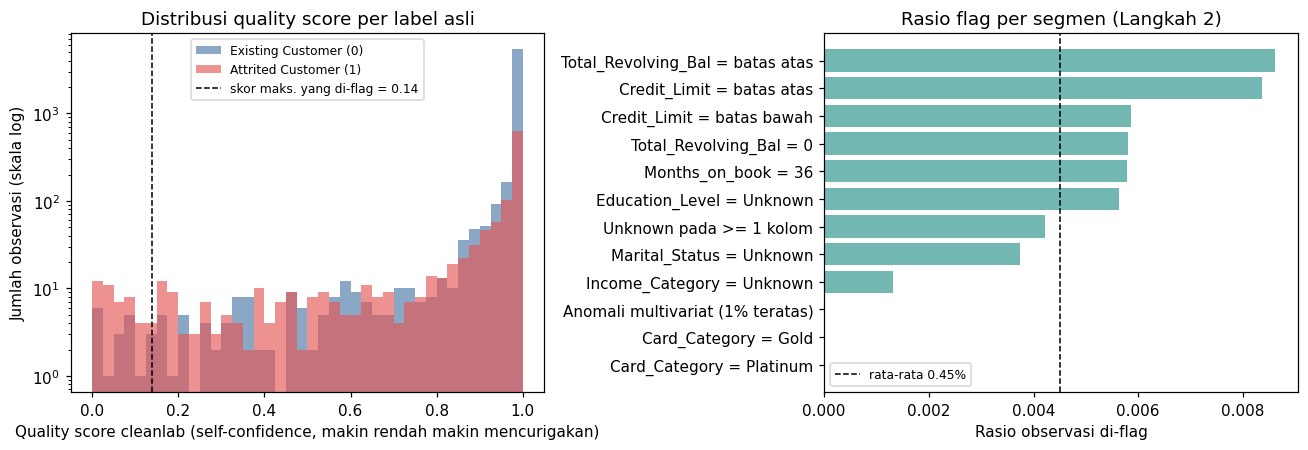

In [ ]:
flagged.to_csv(f"{OUTPUT_DIR}/a4_s4_cleanlab_flagged.csv")
cleanlab_review.to_csv(f"{OUTPUT_DIR}/a4_s4_cleanlab_review.csv")
counts.to_csv(f"{OUTPUT_DIR}/a4_s4_cleanlab_counts.csv")
flag_by_segment.to_csv(f"{OUTPUT_DIR}/a4_s4_cleanlab_flag_by_segment.csv")
filter_sensitivity.to_csv(f"{OUTPUT_DIR}/a4_s4_cleanlab_filter_sensitivity.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.linspace(0, 1, 41)
for c, color in ((0, "#4c78a8"), (1, "#e45756")):
    axes[0].hist(quality_score[labels == c], bins=bins, alpha=0.65, color=color, label=LABEL_NAME[c])
axes[0].set_yscale("log")
axes[0].axvline(flagged.quality_score.max(), color="k", ls="--", lw=1,
                label=f"skor maks. yang di-flag = {flagged.quality_score.max():.2f}")
axes[0].set_xlabel("Quality score cleanlab (self-confidence, makin rendah makin mencurigakan)")
axes[0].set_ylabel("Jumlah observasi (skala log)")
axes[0].set_title("Distribusi quality score per label asli")
axes[0].legend(fontsize=8)

seg_plot = flag_by_segment.sort_values("Rasio flag")
axes[1].barh(seg_plot.index, seg_plot["Rasio flag"], color="#72b7b2")
axes[1].axvline(flag_rate_all, color="k", ls="--", lw=1, label=f"rata-rata {flag_rate_all:.2%}")
axes[1].set_xlabel("Rasio observasi di-flag")
axes[1].set_title("Rasio flag per segmen (Langkah 2)")
axes[1].legend(fontsize=8)
save_path = f"{FIGURE_DIR}/41_cleanlab_quality_scores.png"
plt.tight_layout(); plt.savefig(save_path, bbox_inches="tight", dpi=200); plt.show()


# 5. Perform Data-Centric Experiments

In [ ]:
from sklearn.base import clone

def cross_validate_modified(pipeline, X, y, label, modify_train=None):
    """Fold sama dengan D0 (cv_folds). `modify_train(X_tr, y_tr)` hanya diterapkan pada bagian training
    tiap fold; fold validasi tetap data asli. Tanpa `modify_train`, hasilnya identik dengan D0."""
    rows = []
    for fold in sorted(cv_folds.unique()):
        is_valid = cv_folds == fold
        X_tr, y_tr = X[~is_valid], y[~is_valid]
        if modify_train is not None:
            X_tr, y_tr = modify_train(X_tr, y_tr)
        model = clone(pipeline).fit(X_tr, y_tr)
        prob = model.predict_proba(X[is_valid])[:, 1]
        rows.append({"Eksperimen": label, "Fold": fold,
                     **compute_metrics(y[is_valid], (prob >= 0.5).astype(int), prob)})
    return pd.DataFrame(rows)

check = cross_validate_modified(baseline_pipeline, X_train, y_train, "cek")
assert np.allclose(check[METRIC_ORDER].values, d0_folds[METRIC_ORDER].values), "Fold tidak konsisten dengan D0"

## 5.1 apply_corrections


In [ ]:
ADDITIONAL_CORRECTIONS = {}
ADDITIONAL_REMOVALS    = []

def apply_corrections(X_tr, y_tr):
    X_out, y_out = X_tr.copy(), y_tr.copy()
    review = cleanlab_review
    corrections = {i: int(l) for i, l in review.loc[review["Decision"] == "Correct", "Corrected label"].items()}
    corrections.update(ADDITIONAL_CORRECTIONS)
    removals = set(review.index[review["Decision"] == "Remove"]) | set(ADDITIONAL_REMOVALS)
    for i, new_label in corrections.items():
        if i in y_out.index:
            y_out.loc[i] = new_label
    drop = X_out.index.isin(list(removals))
    return X_out[~drop], y_out[~drop]

X_chk, y_chk = apply_corrections(X_train, y_train)
print(f"apply_corrections pada seluruh training: dihapus {len(X_train) - len(X_chk)}, "
      f"label diubah {int((y_chk != y_train.loc[y_chk.index]).sum())}")


apply_corrections pada seluruh training: dihapus 0, label diubah 0


## 5.2 Jalankan eksperimen sesuai syarat

In [ ]:
D2_LABEL = "D2 Data after justified quality/label corrections"
D3_LABEL = "D3 Corrections + selected imbalance treatment"
run_d2 = D2_APPLICABLE
run_d3 = D2_APPLICABLE and D1_IMPROVES

extra_folds = []
if run_d2:
    extra_folds.append(cross_validate_modified(baseline_pipeline, X_train, y_train, D2_LABEL,
                                               modify_train=apply_corrections))
if run_d3:
    extra_folds.append(cross_validate_modified(IMBALANCE_CANDIDATES[SELECTED_D1], X_train, y_train, D3_LABEL,
                                               modify_train=apply_corrections))

all_folds = pd.concat([d0_folds, d1_folds] + extra_folds, ignore_index=True)
all_folds.to_csv(f"{OUTPUT_DIR}/a4_s5_all_cv_folds.csv", index=False)
cv_mean = summarize_cv(all_folds)

## 5.3 Perbandingan tiap eksperimen terhadap D0 (mean lebih tinggi DAN menang >= 4 dari 5 fold)

In [ ]:
d0_macro = d0_folds.set_index("Fold")["Macro F1"]
rows = []
for name in all_folds["Eksperimen"].unique():
    if name == D0_LABEL:
        continue
    f = all_folds[all_folds["Eksperimen"] == name].set_index("Fold")["Macro F1"]
    rows.append({"Eksperimen": name, "Δ mean Macro F1 vs D0": f.mean() - d0_macro.mean(),
                 "Fold unggul": int((f > d0_macro).sum()),
                 "Lolos aturan": bool(f.mean() > d0_macro.mean() and (f > d0_macro).sum() >= 4)})
vs_d0 = pd.DataFrame(rows).set_index("Eksperimen")
display(vs_d0.round(4))


,Δ mean Macro F1 vs D0,Fold unggul,Lolos aturan
Eksperimen,,,
D1a Class Weighting,-0.0001,3,False
D1b SMOTE,0.0014,2,False
D1c SMOTENC,0.0010,3,False


## 5.4 Dataset final

In [ ]:
passing = vs_d0[vs_d0["Lolos aturan"]]
FINAL_EXPERIMENT = cv_mean.loc[passing.index, "Macro F1 mean"].idxmax() if len(passing) else D0_LABEL
if FINAL_EXPERIMENT == D0_LABEL:
    final_pipeline, final_modify_train = baseline_pipeline, None
elif FINAL_EXPERIMENT == D2_LABEL:
    final_pipeline, final_modify_train = baseline_pipeline, apply_corrections
elif FINAL_EXPERIMENT == D3_LABEL:
    final_pipeline, final_modify_train = IMBALANCE_CANDIDATES[SELECTED_D1], apply_corrections
else:
    final_pipeline, final_modify_train = IMBALANCE_CANDIDATES[FINAL_EXPERIMENT], None
print("FINAL_EXPERIMENT:", FINAL_EXPERIMENT)

FINAL_EXPERIMENT: D0 Assignment #3 baseline data


## 5.5 Tabel eksperimen (format brief) dengan Status dan alasan

In [ ]:
def fmt(name, col):
    return f"{cv_mean.loc[name, col + ' mean']:.4f} ± {cv_mean.loc[name, col + ' std']:.4f}"

def table_row(code, dataset, name, status):
    return {"Experiment": code, "Dataset": dataset, "CV Macro F1": fmt(name, "Macro F1"),
            "CV F1 (churn)": fmt(name, "F1 (churn)"), "CV Recall (churn)": fmt(name, "Recall (churn)"),
            "CV Precision (churn)": fmt(name, "Precision (churn)"), "CV PR-AUC": fmt(name, "PR-AUC"),
            "Status": status}

def status_d1(name):
    r = vs_d0.loc[name]
    verdict = "memperbaiki D0" if r["Lolos aturan"] else "tidak berbeda bermakna"
    sel = " (terbaik di Langkah 3)" if name == SELECTED_D1 else ""
    return (f"Dijalankan{sel}: Δ Macro F1 {r['Δ mean Macro F1 vs D0']:+.4f}, "
            f"unggul {int(r['Fold unggul'])}/5 fold, {verdict}")

table = [table_row("D0", "Assignment #3 baseline data", D0_LABEL, "Baseline")]
for name in IMBALANCE_CANDIDATES:
    table.append(table_row(name.split()[0], f"Data with imbalance treatment ({name[4:]})", name, status_d1(name)))

na = {"CV Macro F1": "-", "CV F1 (churn)": "-", "CV Recall (churn)": "-", "CV Precision (churn)": "-", "CV PR-AUC": "-"}
if run_d2:
    r = vs_d0.loc[D2_LABEL]
    table.append(table_row("D2", "Data after justified quality/label corrections", D2_LABEL,
                           f"Dijalankan: Δ {r['Δ mean Macro F1 vs D0']:+.4f}, unggul {int(r['Fold unggul'])}/5 fold"))
else:
    table.append({"Experiment": "D2", "Dataset": "Data after justified quality/label corrections", **na,
                  "Status": f"Tidak dijalankan: review cleanlab ({int(counts.loc['Reviewed','Jumlah'])} direview) menghasilkan "
                            f"0 Correct dan 0 Remove ({int(counts.loc['Unresolved','Jumlah'])} Unresolved, "
                            f"{int(counts.loc['Retained (Keep)','Jumlah'])} Keep); tidak ada bukti independen untuk mengubah data, "
                            f"sehingga D2 identik dengan D0"})
if run_d3:
    r = vs_d0.loc[D3_LABEL]
    table.append(table_row("D3", "Corrections + selected imbalance treatment", D3_LABEL,
                           f"Dijalankan: Δ {r['Δ mean Macro F1 vs D0']:+.4f}, unggul {int(r['Fold unggul'])}/5 fold"))
else:
    why = "D2 tidak dijalankan (tidak ada koreksi)" if not run_d2 else "D1_IMPROVES = False"
    table.append({"Experiment": "D3", "Dataset": "Corrections + selected imbalance treatment", **na,
                  "Status": f"Tidak dijalankan: {why} dan imbalance treatment tidak memperbaiki D0 secara konsisten "
                            f"({SELECTED_D1}: unggul {int(vs_d0.loc[SELECTED_D1,'Fold unggul'])}/5 fold)"})
experiment_table = pd.DataFrame(table).set_index("Experiment")
experiment_table.to_csv(f"{OUTPUT_DIR}/a4_experiment_table.csv")
with pd.option_context("display.max_colwidth", None):
    display(experiment_table)



,Dataset,CV Macro F1,CV F1 (churn),CV Recall (churn),CV Precision (churn),CV PR-AUC,Status
Experiment,,,,,,,
D0,Assignment #3 baseline data,0.9464 ± 0.0069,0.9096 ± 0.0119,0.8894 ± 0.0226,0.9311 ± 0.0022,0.9723 ± 0.0068,Baseline
D1a,Data with imbalance treatment (Class Weighting),0.9463 ± 0.0046,0.9103 ± 0.0079,0.9315 ± 0.0197,0.8903 ± 0.0083,0.9715 ± 0.0072,"Dijalankan: Δ Macro F1 -0.0001, unggul 3/5 fold, tidak berbeda bermakna"
D1b,Data with imbalance treatment (SMOTE),0.9478 ± 0.0046,0.9122 ± 0.0080,0.9052 ± 0.0255,0.9202 ± 0.0125,0.9720 ± 0.0057,"Dijalankan (terbaik di Langkah 3): Δ Macro F1 +0.0014, unggul 2/5 fold, tidak berbeda bermakna"
D1c,Data with imbalance treatment (SMOTENC),0.9474 ± 0.0058,0.9117 ± 0.0100,0.9131 ± 0.0257,0.9110 ± 0.0090,0.9708 ± 0.0060,"Dijalankan: Δ Macro F1 +0.0010, unggul 3/5 fold, tidak berbeda bermakna"
D2,Data after justified quality/label corrections,-,-,-,-,-,"Tidak dijalankan: review cleanlab (30 direview) menghasilkan 0 Correct dan 0 Remove (24 Unresolved, 6 Keep); tidak ada bukti independen untuk mengubah data, sehingga D2 identik dengan D0"
D3,Corrections + selected imbalance treatment,-,-,-,-,-,Tidak dijalankan: D2 tidak dijalankan (tidak ada koreksi) dan imbalance treatment tidak memperbaiki D0 secara konsisten (D1b SMOTE: unggul 2/5 fold)


In [ ]:
final_check = pd.DataFrame({"Nilai": {
    "FINAL_EXPERIMENT": FINAL_EXPERIMENT,
    "Aturan": "mean Macro F1 > D0 dan unggul di >= 4 dari 5 fold",
    "Kandidat lolos aturan": ", ".join(passing.index) if len(passing) else "tidak ada",
    "Data training diubah": final_modify_train is not None,
    "Dataset final": "D0 (data A3 tanpa perubahan)" if FINAL_EXPERIMENT == D0_LABEL else FINAL_EXPERIMENT}})
final_check.to_csv(f"{OUTPUT_DIR}/a4_s5_final_check.csv")
display(final_check)

,Nilai
FINAL_EXPERIMENT,D0 Assignment #3 baseline data
Aturan,mean Macro F1 > D0 dan unggul di >= 4 dari 5 fold
Kandidat lolos aturan,tidak ada
Data training diubah,False
Dataset final,D0 (data A3 tanpa perubahan)


## 5.1 Macro F1 per fold

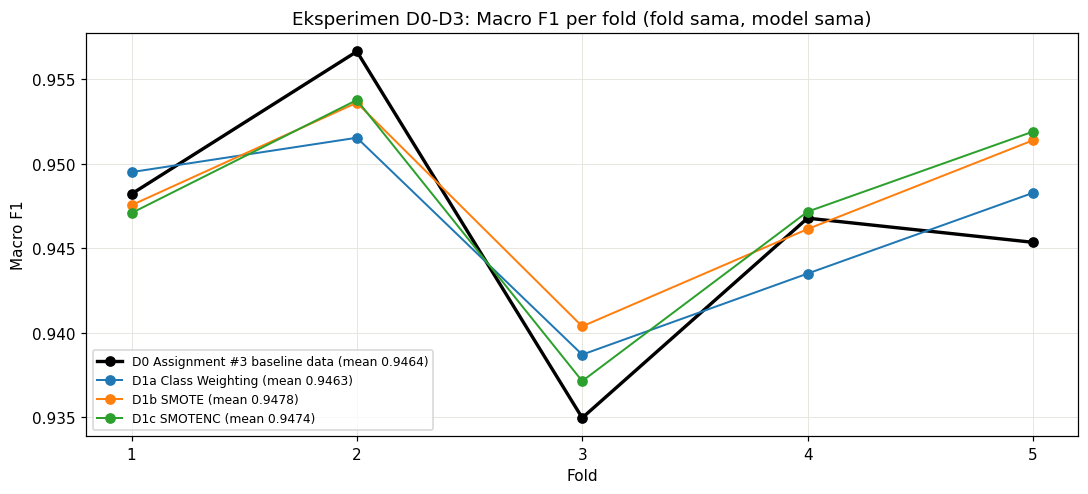

In [ ]:
pivot = all_folds.pivot(index="Fold", columns="Eksperimen", values="Macro F1")[list(all_folds["Eksperimen"].unique())]
fig, ax = plt.subplots(figsize=(10, 4.6))
for name in pivot.columns:
    ax.plot(pivot.index, pivot[name], marker="o", lw=2.2 if name == D0_LABEL else 1.3,
            color="k" if name == D0_LABEL else None, label=f"{name} (mean {pivot[name].mean():.4f})")
ax.set_xticks(pivot.index); ax.set_xlabel("Fold"); ax.set_ylabel("Macro F1")
ax.set_title("Eksperimen D0-D3: Macro F1 per fold (fold sama, model sama)")
ax.legend(fontsize=8, loc="lower left"); ax.grid(color="#e5e4df", lw=0.6)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/51_experiment_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

# 6. Interpret the Model

## 6.1 Model final dan input SHAP

In [ ]:
X_fit, y_fit = (X_train, y_train) if final_modify_train is None else final_modify_train(X_train, y_train)
final_model = clone(final_pipeline).fit(X_fit, y_fit)

encoder, scaler, xgb_model = (final_model.named_steps[k] for k in ("encode", "scale", "model"))
model_input = scaler.transform(encoder.transform(X_test))          # persis yang dilihat model (21 fitur, sudah di-scale)
display_input = encoder.transform(X_test)                           # nilai fitur sebelum scaling (Unknown = -1 pada ordinal)
feature_names = list(model_input.columns)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(model_input)                    # log-odds churn, bentuk (3039, 21)
base_value = float(np.ravel(explainer.expected_value)[0])

# Cek aditivitas: base + jumlah SHAP = log-odds prediksi model
margin = xgb_model.predict(model_input, output_margin=True)
assert np.allclose(base_value + shap_values.sum(axis=1), margin, atol=1e-3), "SHAP tidak aditif"

test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)
outcome = pd.Series(np.select(
    [(y_test == 1) & (test_pred == 1), (y_test == 0) & (test_pred == 0),
     (y_test == 1) & (test_pred == 0), (y_test == 0) & (test_pred == 1)],
    ["TP", "TN", "FN", "FP"], default="?"), index=X_test.index, name="outcome")
print("Outcome test set:", outcome.value_counts().to_dict())

explanation = shap.Explanation(values=shap_values, base_values=np.full(len(shap_values), base_value),
                               data=display_input.to_numpy(), feature_names=feature_names)

Outcome test set: {'TN': 2521, 'TP': 425, 'FN': 63, 'FP': 30}


## Global

,mean |SHAP|,persen,persen kumulatif,arah (korelasi nilai fitur vs SHAP)
Total_Trans_Ct,3.2879,30.805201,30.805201,-0.9505
Total_Trans_Amt,1.9897,18.642099,49.447300,0.5567
Total_Revolving_Bal,1.1456,10.732900,60.180199,-0.6285
Total_Amt_Chng_Q4_Q1,0.6717,6.293700,66.473801,-0.6344
Total_Ct_Chng_Q4_Q1,0.6709,6.286000,72.759804,-0.8650
Months_Inactive_12_mon,0.5211,4.881800,77.641602,0.8002
Total_Relationship_Count,0.5050,4.731500,82.373100,-0.8091
Customer_Age,0.3865,3.621100,85.994202,0.2067
Contacts_Count_12_mon,0.3387,3.173500,89.167801,0.8473
Credit_Limit,0.2256,2.113300,91.281097,-0.1564


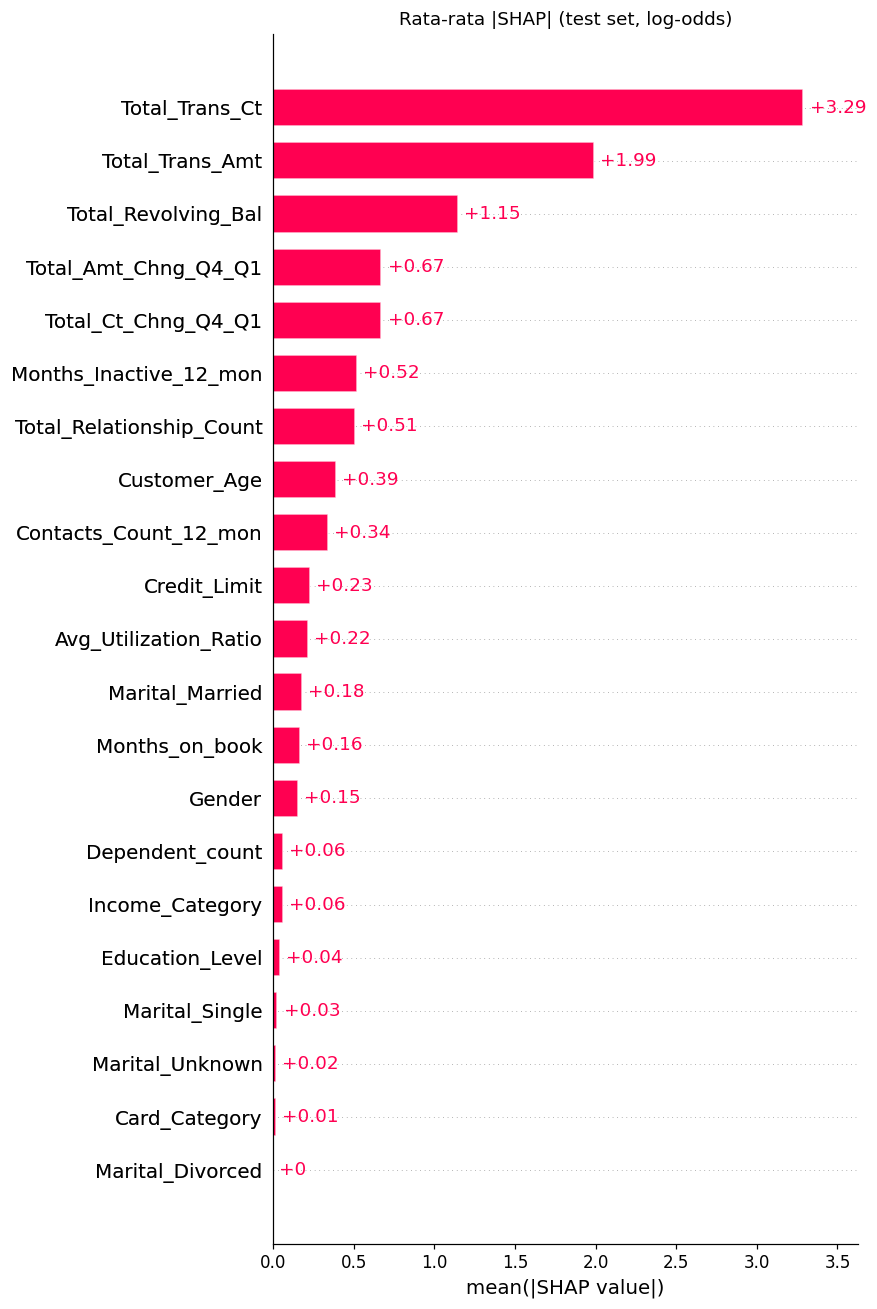

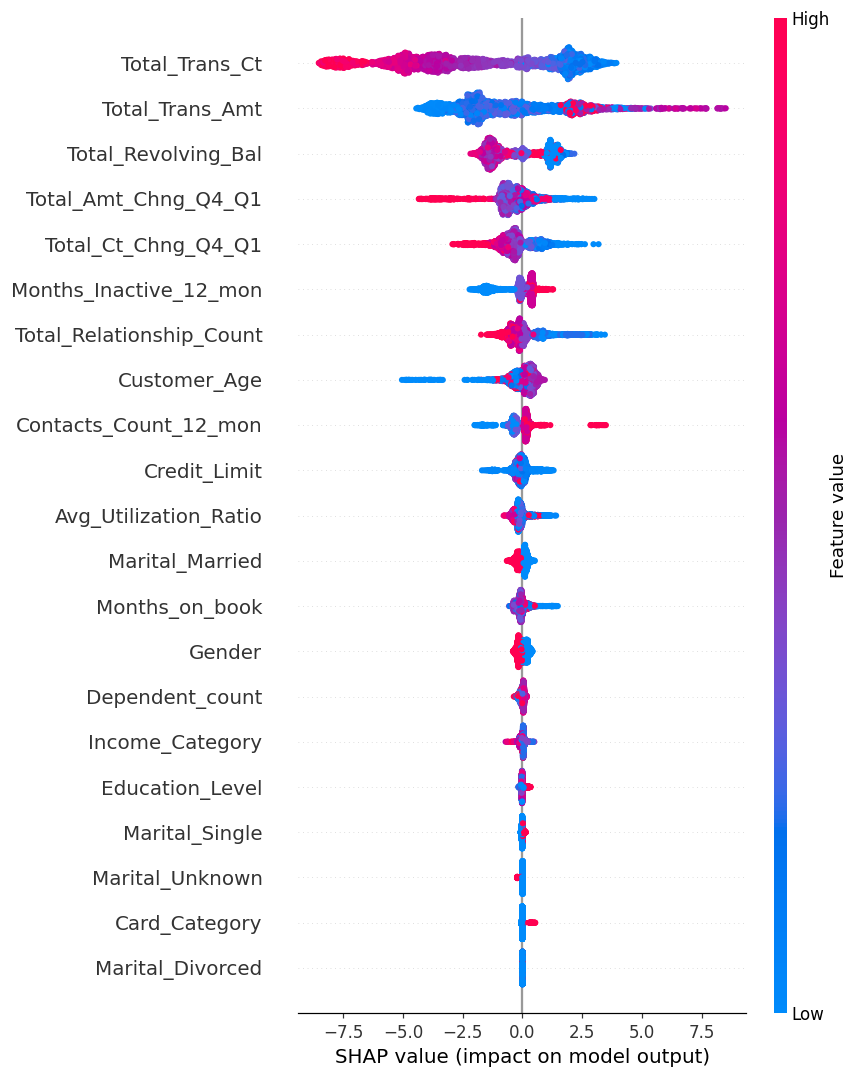

<Figure size 704x528 with 0 Axes>

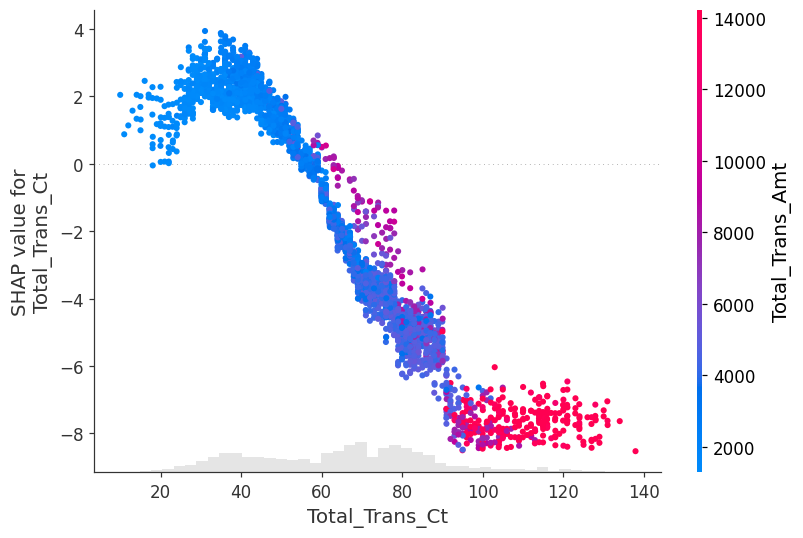

<Figure size 704x528 with 0 Axes>

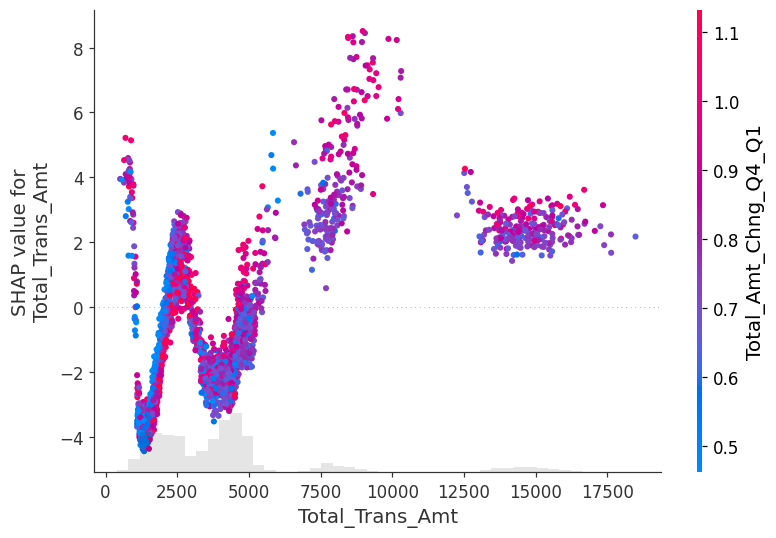

<Figure size 704x528 with 0 Axes>

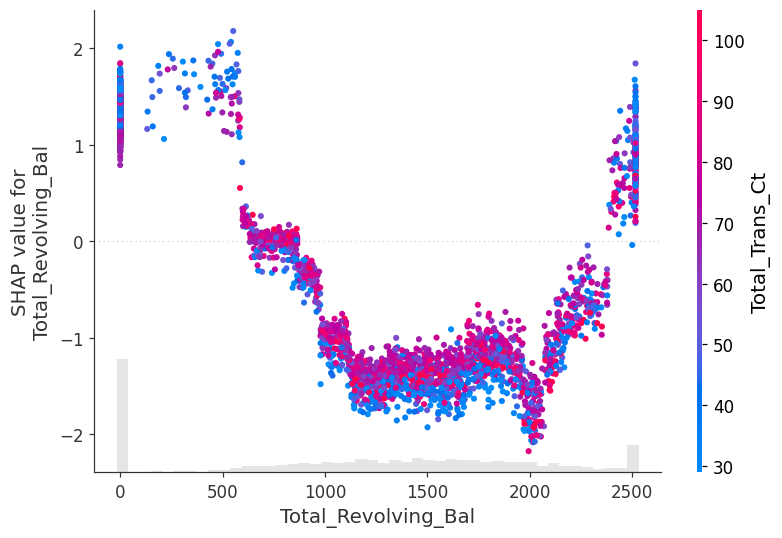

In [ ]:
shap_importance = (pd.DataFrame({"mean |SHAP|": np.abs(shap_values).mean(axis=0)}, index=feature_names)
                   .sort_values("mean |SHAP|", ascending=False))
shap_importance["persen"] = 100 * shap_importance["mean |SHAP|"] / shap_importance["mean |SHAP|"].sum()
shap_importance["persen kumulatif"] = shap_importance["persen"].cumsum()
shap_importance["arah (korelasi nilai fitur vs SHAP)"] = [
    float(np.corrcoef(display_input[f], shap_values[:, feature_names.index(f)])[0, 1])
    if display_input[f].nunique() > 1 else np.nan for f in shap_importance.index]
shap_importance.to_csv(f"{OUTPUT_DIR}/a4_s6_shap_importance.csv")
display(shap_importance.round(4))

plt.figure(); shap.plots.bar(explanation, max_display=21, show=False)
plt.title("Rata-rata |SHAP| (test set, log-odds)"); plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/61_shap_bar.png", dpi=200, bbox_inches="tight"); plt.show()

plt.figure(); shap.plots.beeswarm(explanation, max_display=21, show=False)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/62_shap_beeswarm.png", dpi=200, bbox_inches="tight"); plt.show()

for feature in shap_importance.index[:3]:
    plt.figure(); shap.plots.scatter(explanation[:, feature], color=explanation, show=False)
    plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/63_shap_dependence_{feature}.png", dpi=200, bbox_inches="tight"); plt.show()

## 6.3 Lokal
kasus dipilih dengan aturan tetap (bukan manual)

,0,1,2,3,4,5,6,7
kasus,TP_tipikal,TN_tipikal,FN_paling_yakin,FN_dekat_batas,FP_paling_yakin,CL_9187_Attrited_diprediksi_Existing,CL_2411_Attrited_Keep,CL_1826_Existing_diprediksi_Attrited
aturan pemilihan,TP dengan p(churn) paling dekat median seluruh TP,TN dengan p(churn) paling dekat median seluruh TN,FN dengan p(churn) terendah (churn terlewat pa...,FN dengan p(churn) tertinggi (nyaris tertangkap),FP dengan p(churn) tertinggi (salah alarm pali...,Observasi training berskor cleanlab terendah (...,Observasi training berskor cleanlab terendah (...,Observasi training berskor cleanlab terendah (...
indeks baris,813,2668,8623,7491,1039,9187,2411,1826
label asli,1,0,1,1,0,1,1,0
p(churn),0.9885,0.0003,0.006,0.4967,0.9994,0.0003,0.0053,0.9956
f(x) log-odds,4.451,-8.035,-5.111,-0.013,7.395,-8.107,-5.242,5.412
kontributor 1,Total_Trans_Amt=732 (+3.96),Total_Trans_Ct=77 (-4.18),Months_Inactive_12_mon=1 (-1.72),Total_Revolving_Bal=193 (+1.73),Total_Trans_Amt=902 (+3.94),Total_Trans_Ct=65 (-3.15),Total_Trans_Amt=1.31e+03 (-3.76),Total_Amt_Chng_Q4_Q1=0.32 (+3.14)
kontributor 2,Total_Trans_Ct=21 (+1.70),Total_Trans_Amt=4.04e+03 (-2.02),Total_Revolving_Bal=0 (+1.00),Total_Trans_Ct=54 (+0.81),Total_Trans_Ct=31 (+3.11),Total_Trans_Amt=4.04e+03 (-2.69),Total_Trans_Ct=32 (+1.61),Total_Trans_Ct=40 (+2.26)
kontributor 3,Total_Revolving_Bal=0 (+1.36),Avg_Utilization_Ratio=0.026 (+0.92),Total_Relationship_Count=6 (-0.96),Avg_Utilization_Ratio=0.042 (+0.43),Total_Revolving_Bal=0 (+1.75),Total_Relationship_Count=1 (+2.03),Avg_Utilization_Ratio=0.023 (+0.84),Total_Trans_Amt=1.72e+03 (-1.46)
kontributor 4,Contacts_Count_12_mon=1 (-0.52),Total_Amt_Chng_Q4_Q1=0.695 (-0.57),Total_Trans_Amt=4.52e+03 (-0.96),Total_Relationship_Count=4 (-0.43),Months_Inactive_12_mon=1 (-0.90),Months_Inactive_12_mon=1 (-1.44),Total_Relationship_Count=5 (-0.81),Total_Revolving_Bal=0 (+1.37)


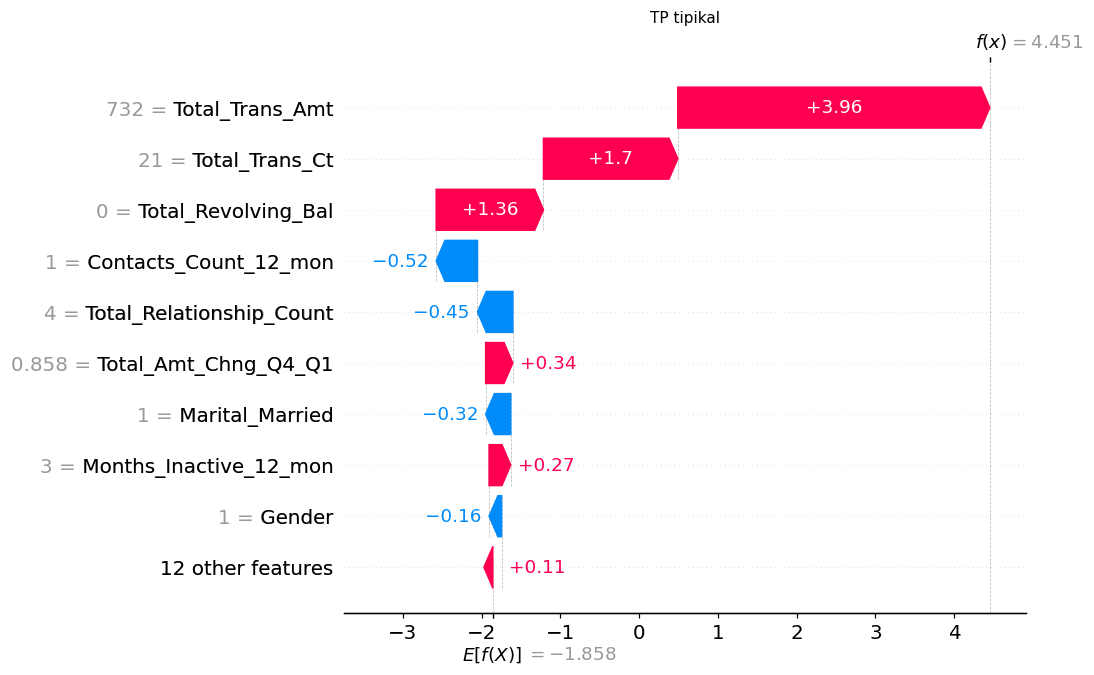

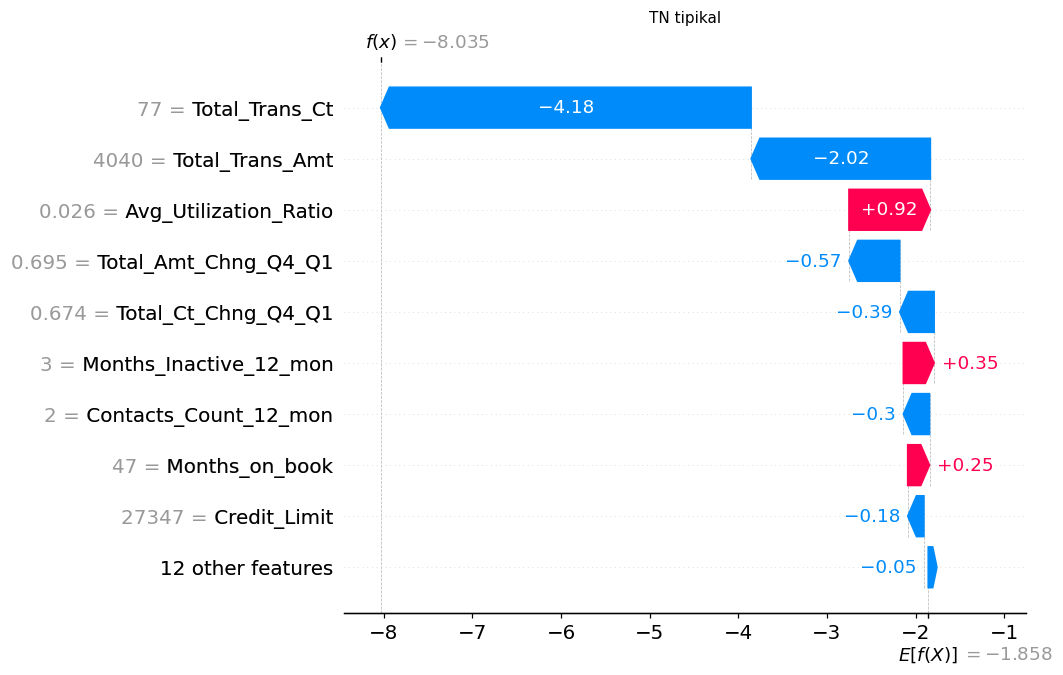

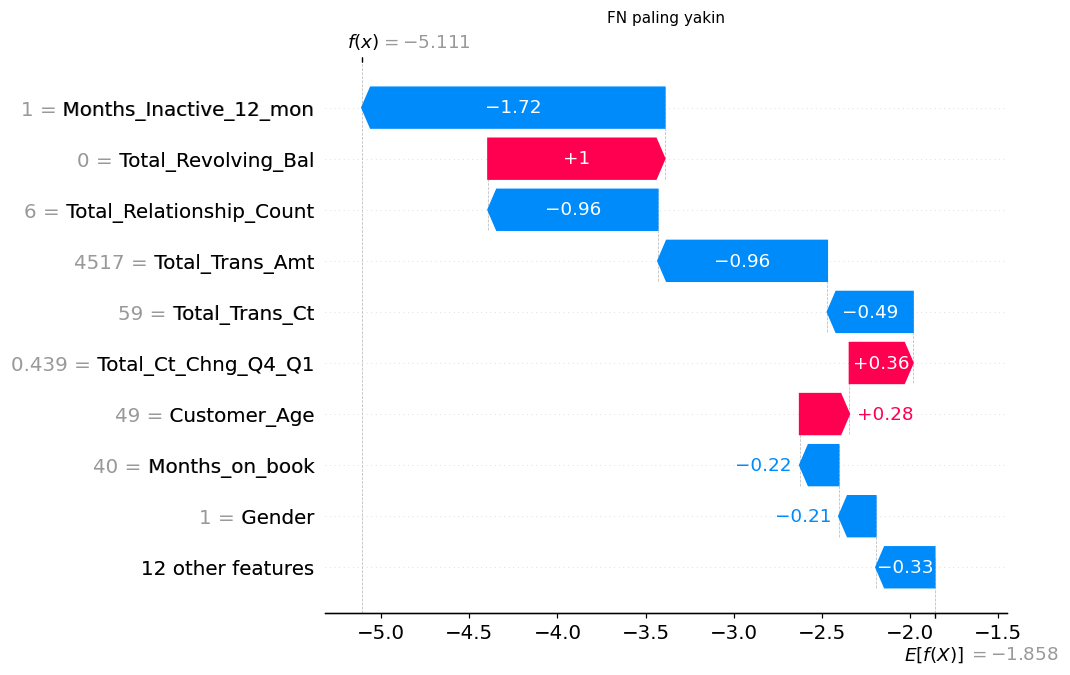

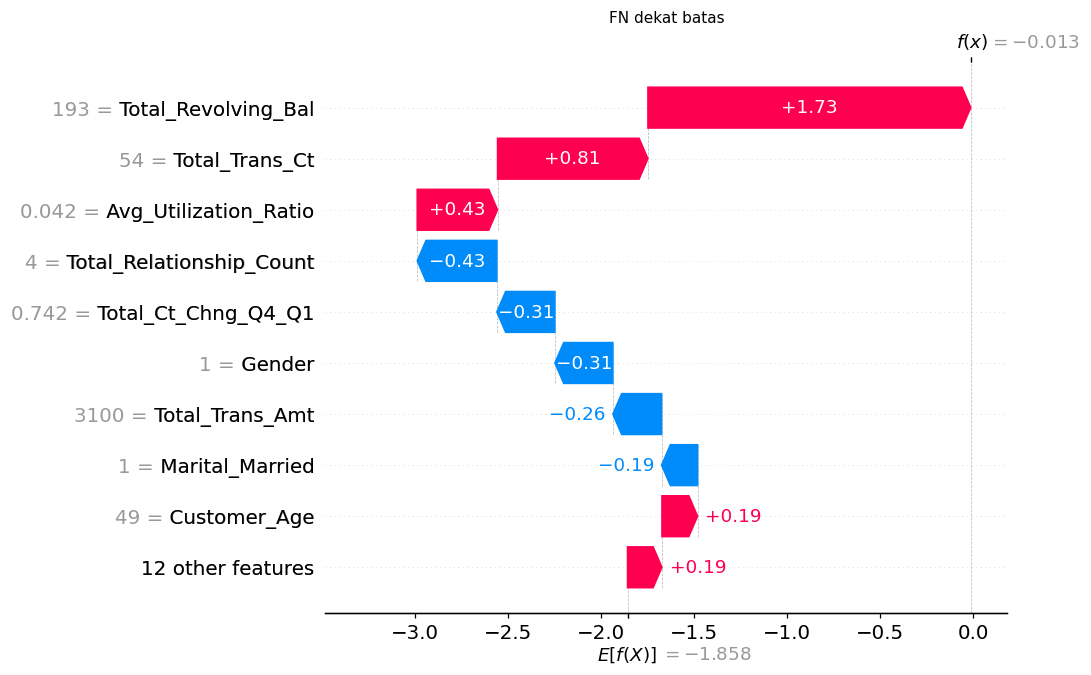

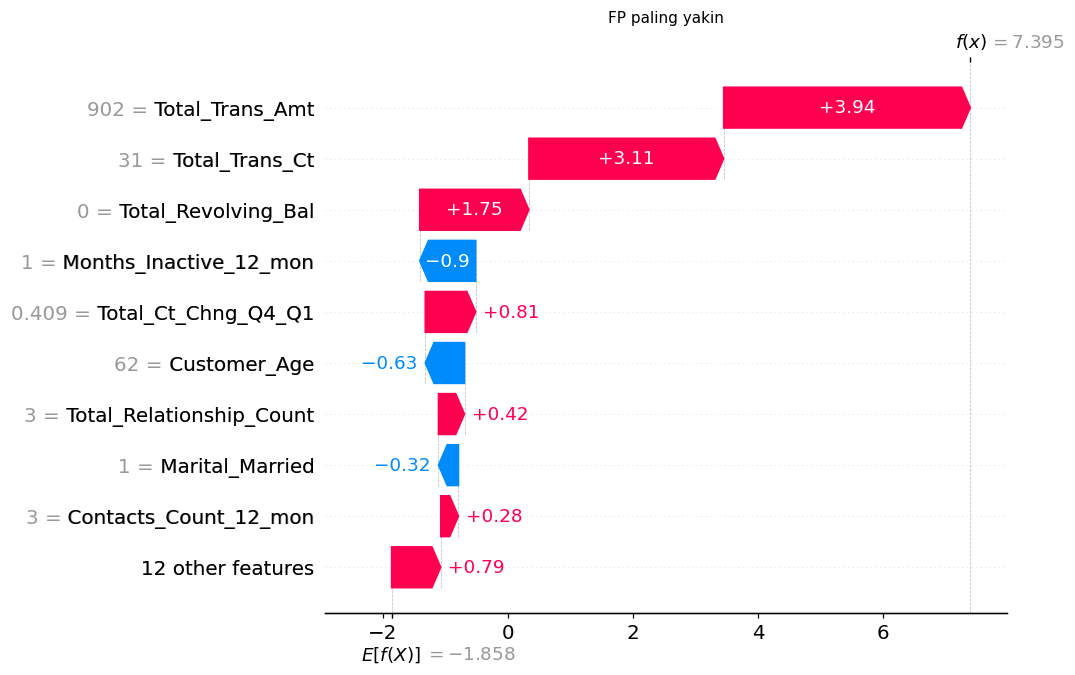

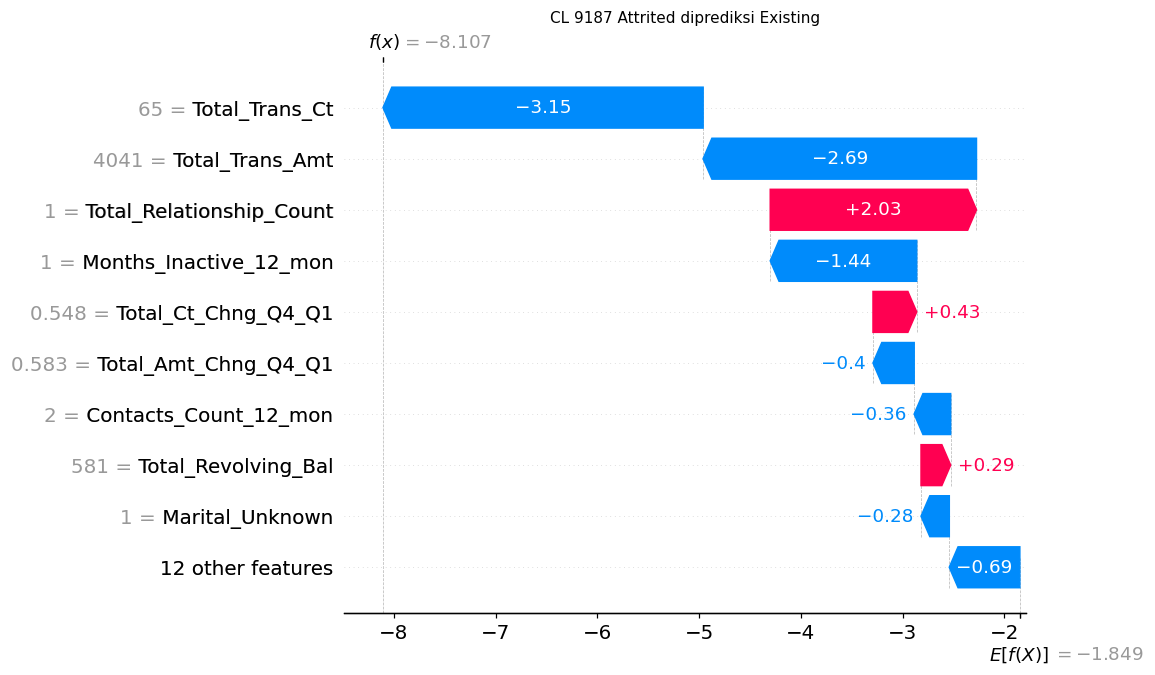

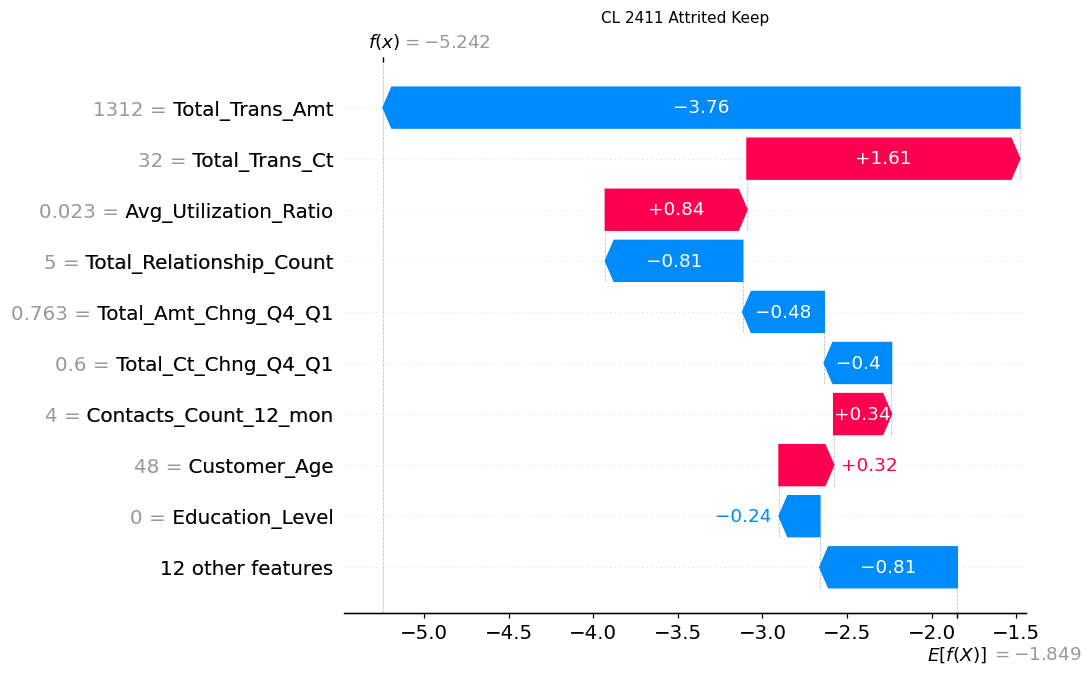

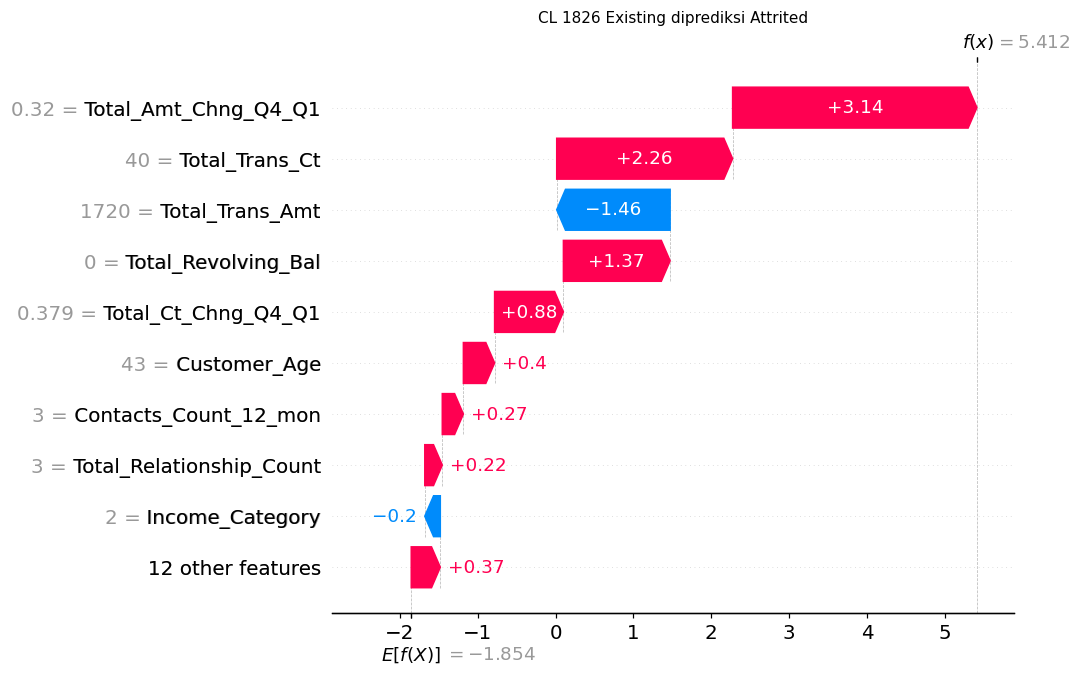

In [ ]:
p = pd.Series(test_prob, index=X_test.index)
def closest_to(series, target): return (series - target).abs().idxmin()
local_rules = [
    ("TP_tipikal",         "TP dengan p(churn) paling dekat median seluruh TP",   closest_to(p[outcome == "TP"], p[outcome == "TP"].median())),
    ("TN_tipikal",         "TN dengan p(churn) paling dekat median seluruh TN",   closest_to(p[outcome == "TN"], p[outcome == "TN"].median())),
    ("FN_paling_yakin",    "FN dengan p(churn) terendah (churn terlewat paling yakin)", p[outcome == "FN"].idxmin()),
    ("FN_dekat_batas",     "FN dengan p(churn) tertinggi (nyaris tertangkap)",     p[outcome == "FN"].idxmax()),
    ("FP_paling_yakin",    "FP dengan p(churn) tertinggi (salah alarm paling yakin)", p[outcome == "FP"].idxmax()),
]
local_rows, local_explanations = [], {}
def contributions_row(name, rule, idx, label, prob, exp_one):
    order = np.argsort(-np.abs(exp_one.values))[:5]
    row = {"kasus": name, "aturan pemilihan": rule, "indeks baris": idx, "label asli": int(label),
           "p(churn)": round(float(prob), 4), "f(x) log-odds": round(float(exp_one.base_values + exp_one.values.sum()), 3)}
    for rank, j in enumerate(order, start=1):
        row[f"kontributor {rank}"] = f"{exp_one.feature_names[j]}={exp_one.data[j]:.3g} ({exp_one.values[j]:+.2f})"
    return row

for name, rule, idx in local_rules:
    pos = X_test.index.get_loc(idx)
    local_explanations[name] = explanation[pos]
    local_rows.append(contributions_row(name, rule, idx, y_test.loc[idx], test_prob[pos], explanation[pos]))

# Observasi training dari Langkah 4 (skor cleanlab terendah). Penjelasan memakai model fold OOF
# yang tidak pernah melihat observasi itu, konsisten dengan skor cleanlab.
from a4_common import get_cv
cleanlab_cases = {"CL_9187_Attrited_diprediksi_Existing": 9187,
                  "CL_2411_Attrited_Keep":                  2411,
                  "CL_1826_Existing_diprediksi_Attrited":   1826}
fold_splits = list(get_cv().split(X_train, y_train))
for name, idx in cleanlab_cases.items():
    pos_tr = X_train.index.get_loc(idx)
    tr_idx, _ = next(s for s in fold_splits if pos_tr in s[1])
    fm = clone(final_pipeline).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    row_raw = fm.named_steps["encode"].transform(X_train.iloc[[pos_tr]])
    row_in = fm.named_steps["scale"].transform(row_raw)
    ex = shap.TreeExplainer(fm.named_steps["model"])
    sv = ex.shap_values(row_in)[0]
    e1 = shap.Explanation(values=sv, base_values=float(np.ravel(ex.expected_value)[0]),
                          data=row_raw.to_numpy()[0], feature_names=list(row_in.columns))
    local_explanations[name] = e1
    prob_fm = float(fm.predict_proba(X_train.iloc[[pos_tr]])[0, 1])
    local_rows.append(contributions_row(name, "Observasi training berskor cleanlab terendah (model fold OOF)", idx, y_train.loc[idx], prob_fm, e1))

local_cases = pd.DataFrame(local_rows)
local_cases.to_csv(f"{OUTPUT_DIR}/a4_s6_local_cases.csv", index=False)
display(local_cases.T)

for name, e1 in local_explanations.items():
    plt.figure(); shap.plots.waterfall(e1, max_display=10, show=False)
    plt.title(name.replace("_", " "), fontsize=10)
    plt.savefig(f"{FIGURE_DIR}/64_shap_local_{name}.png", dpi=200, bbox_inches="tight"); plt.show()

## 6.4 Pemeriksaan kebocoran dan fitur bermasalah

In [ ]:
train_encoded = encoder.transform(X_train)
single_auc = pd.Series({f: roc_auc_score(y_train, train_encoded[f]) for f in train_encoded.columns})
single_auc = pd.DataFrame({"AUC": single_auc, "AUC (arah disesuaikan)": np.maximum(single_auc, 1 - single_auc)})
nb_cols = [c for c in raw_dataset.columns if c.startswith("Naive_Bayes_Classifier")]
nb_auc = pd.DataFrame({"AUC": {c: roc_auc_score(y_train, raw_dataset.loc[X_train.index, c]) for c in nb_cols}})
nb_auc["AUC (arah disesuaikan)"] = np.maximum(nb_auc["AUC"], 1 - nb_auc["AUC"])
single_auc_all = pd.concat([single_auc, nb_auc.rename(index=lambda c: c[:40] + "… (dibuang di A2)")]
                           ).sort_values("AUC (arah disesuaikan)", ascending=False)
single_auc_all.to_csv(f"{OUTPUT_DIR}/a4_s6_single_feature_auc.csv")
display(single_auc_all.round(4))

top_features = list(shap_importance.index[:8])
corr_top = train_encoded[top_features].corr().round(2)
corr_top.to_csv(f"{OUTPUT_DIR}/a4_s6_top_feature_correlation.csv")
display(corr_top)

,AUC,AUC (arah disesuaikan)
Naive_Bayes_Classifier_Attrition_Flag_Ca… (dibuang di A2),0.0000,1.0000
Naive_Bayes_Classifier_Attrition_Flag_Ca… (dibuang di A2),1.0000,1.0000
Total_Trans_Ct,0.1980,0.8020
Total_Ct_Chng_Q4_Q1,0.2493,0.7507
Avg_Utilization_Ratio,0.3066,0.6934
Total_Revolving_Bal,0.3092,0.6908
Total_Trans_Amt,0.3161,0.6839
Contacts_Count_12_mon,0.6471,0.6471
Months_Inactive_12_mon,0.6328,0.6328
Total_Relationship_Count,0.3774,0.6226


,Total_Trans_Ct,Total_Trans_Amt,Total_Revolving_Bal,Total_Amt_Chng_Q4_Q1,Total_Ct_Chng_Q4_Q1,Months_Inactive_12_mon,Total_Relationship_Count,Customer_Age
Total_Trans_Ct,1.00,0.81,0.06,0.00,0.12,-0.04,-0.24,-0.07
Total_Trans_Amt,0.81,1.00,0.07,0.03,0.09,-0.04,-0.34,-0.05
Total_Revolving_Bal,0.06,0.07,1.00,0.06,0.09,-0.05,0.02,0.03
Total_Amt_Chng_Q4_Q1,0.00,0.03,0.06,1.00,0.38,-0.03,0.05,-0.05
Total_Ct_Chng_Q4_Q1,0.12,0.09,0.09,0.38,1.00,-0.04,0.04,-0.00
Months_Inactive_12_mon,-0.04,-0.04,-0.05,-0.03,-0.04,1.00,0.00,0.04
Total_Relationship_Count,-0.24,-0.34,0.02,0.05,0.04,0.00,1.00,-0.01
Customer_Age,-0.07,-0.05,0.03,-0.05,-0.00,0.04,-0.01,1.00


# 7. Connect Model Interpretation to Data Quality

In [ ]:
# setup
assert final_modify_train is None, "Langkah 7 memakai D0 (data final = D0); sesuaikan bila data final berubah"
KEY = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Revolving_Bal", "Total_Ct_Chng_Q4_Q1",
       "Total_Amt_Chng_Q4_Q1", "Months_Inactive_12_mon", "Total_Relationship_Count"]
ACTIVITY = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Ct_Chng_Q4_Q1", "Total_Amt_Chng_Q4_Q1", "Months_Inactive_12_mon"]
S = pd.DataFrame(shap_values, index=X_test.index, columns=feature_names)       # SHAP test set (Langkah 6)
D = display_input.copy(); D.index = X_test.index
test_error = (test_pred != y_test.to_numpy())

## 7.1 Ketergantungan pada fitur dominan
ablation CV (pipeline D0, fold sama, hanya training set)

,Fitur dibuang,Macro F1 mean,F1 (churn) mean,Recall (churn) mean,Precision (churn) mean,ROC-AUC mean,PR-AUC mean,Macro F1 std,Δ Macro F1 vs D0,Δ F1 churn vs D0,Fold dengan Macro F1 turun
Skenario,,,,,,,,,,,
D0 (semua fitur),-,0.9464,0.9096,0.8894,0.9311,0.9935,0.9723,0.0069,0.0000,0.0000,0
Tanpa Total_Trans_Ct,Total_Trans_Ct,0.9321,0.8854,0.8578,0.9153,0.9871,0.9508,0.0088,-0.0142,-0.0242,5
Tanpa Total_Trans_Amt,Total_Trans_Amt,0.8929,0.8184,0.7752,0.8679,0.9710,0.9004,0.0071,-0.0535,-0.0912,5
Tanpa Total_Trans_Ct + Total_Trans_Amt,"Total_Trans_Ct, Total_Trans_Amt",0.8235,0.6976,0.6242,0.7910,0.9292,0.7955,0.0216,-0.1229,-0.2119,5
Tanpa perubahan Q4-Q1 (Ct_Chng + Amt_Chng),"Total_Ct_Chng_Q4_Q1, Total_Amt_Chng_Q4_Q1",0.9230,0.8700,0.8437,0.8983,0.9869,0.9474,0.0107,-0.0234,-0.0396,5
Tanpa Months_Inactive_12_mon,Months_Inactive_12_mon,0.9407,0.9000,0.8780,0.9235,0.9929,0.9678,0.0101,-0.0057,-0.0096,5
Tanpa Total_Revolving_Bal,Total_Revolving_Bal,0.9438,0.9051,0.8806,0.9314,0.9926,0.9685,0.0088,-0.0026,-0.0045,2
Tanpa Total_Revolving_Bal + Avg_Utilization_Ratio,"Total_Revolving_Bal, Avg_Utilization_Ratio",0.9399,0.8985,0.8753,0.9234,0.9909,0.9613,0.0082,-0.0065,-0.0111,5
Tanpa 5 fitur aktivitas 12 bulan,"Total_Trans_Ct, Total_Trans_Amt, Total_Ct_Chng...",0.6894,0.4574,0.3609,0.6272,0.8359,0.5760,0.0112,-0.2570,-0.4522,5


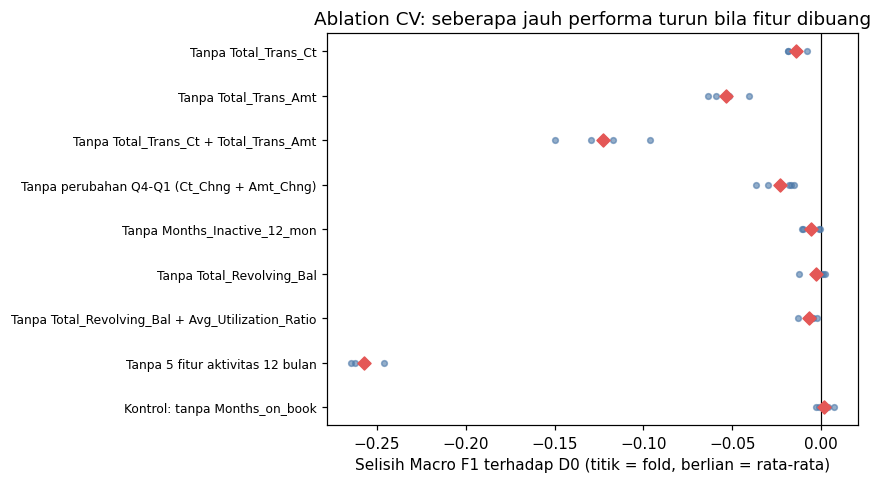

In [ ]:
ABLATIONS = {
    "Tanpa Total_Trans_Ct":                              ["Total_Trans_Ct"],
    "Tanpa Total_Trans_Amt":                             ["Total_Trans_Amt"],
    "Tanpa Total_Trans_Ct + Total_Trans_Amt":            ["Total_Trans_Ct", "Total_Trans_Amt"],
    "Tanpa perubahan Q4-Q1 (Ct_Chng + Amt_Chng)":        ["Total_Ct_Chng_Q4_Q1", "Total_Amt_Chng_Q4_Q1"],
    "Tanpa Months_Inactive_12_mon":                      ["Months_Inactive_12_mon"],
    "Tanpa Total_Revolving_Bal":                         ["Total_Revolving_Bal"],
    "Tanpa Total_Revolving_Bal + Avg_Utilization_Ratio": ["Total_Revolving_Bal", "Avg_Utilization_Ratio"],
    "Tanpa 5 fitur aktivitas 12 bulan":                  ACTIVITY,
    "Kontrol: tanpa Months_on_book":                     ["Months_on_book"],
}
BASE_NAME = "D0 (semua fitur)"
abl_folds = [cross_validate_pipeline(final_pipeline, X_train, y_train, BASE_NAME)]
for name, cols in ABLATIONS.items():
    abl_folds.append(cross_validate_pipeline(final_pipeline, X_train.drop(columns=cols), y_train, name))
abl_folds = pd.concat(abl_folds, ignore_index=True)
abl_mean = summarize_cv(abl_folds)
base_f = abl_folds[abl_folds.Eksperimen == BASE_NAME].set_index("Fold")[METRIC_ORDER]
rows = []
for name in abl_mean.index:
    f = abl_folds[abl_folds.Eksperimen == name].set_index("Fold")[METRIC_ORDER]
    diff = f - base_f
    rows.append({"Skenario": name, "Fitur dibuang": ", ".join(ABLATIONS.get(name, [])) or "-",
                 **{f"{m} mean": abl_mean.loc[name, f"{m} mean"] for m in
                    ("Macro F1", "F1 (churn)", "Recall (churn)", "Precision (churn)", "ROC-AUC", "PR-AUC")},
                 "Macro F1 std": abl_mean.loc[name, "Macro F1 std"],
                 "Δ Macro F1 vs D0": diff["Macro F1"].mean(), "Δ F1 churn vs D0": diff["F1 (churn)"].mean(),
                 "Fold dengan Macro F1 turun": int((diff["Macro F1"] < 0).sum())})
ablation = pd.DataFrame(rows).set_index("Skenario")
ablation.to_csv(f"{OUTPUT_DIR}/a4_s7_ablation.csv")
display(ablation.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
names = [n for n in ablation.index if n != BASE_NAME][::-1]
for k, n in enumerate(names):
    diffs = (abl_folds[abl_folds.Eksperimen == n].set_index("Fold")["Macro F1"] - base_f["Macro F1"])
    ax.scatter(diffs, [k] * len(diffs), s=14, color="#4c78a8", alpha=0.6, zorder=3)
    ax.scatter(diffs.mean(), k, marker="D", color="#e45756", zorder=4)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Selisih Macro F1 terhadap D0 (titik = fold, berlian = rata-rata)")
ax.set_title("Ablation CV: seberapa jauh performa turun bila fitur dibuang")
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/71_ablation.png", dpi=200, bbox_inches="tight"); plt.show()

## 7.2 Asal kesalahan
SHAP dan profil fitur per kelompok outcome (test set)

Mean SHAP per kelompok (fitur utama)


Fitur,Total_Trans_Ct,Total_Trans_Amt,Total_Revolving_Bal,Total_Ct_Chng_Q4_Q1,Total_Amt_Chng_Q4_Q1,Months_Inactive_12_mon,Total_Relationship_Count
Kelompok,,,,,,,
FN,0.31,0.33,0.03,-0.13,0.20,-0.12,-0.16
FP,1.57,0.42,0.63,-0.06,0.23,0.15,0.50
TN,-2.67,-0.99,-0.52,-0.41,-0.48,-0.24,-0.05
TP,1.72,1.84,0.91,0.45,0.34,0.22,0.59


Median nilai fitur per kelompok


Fitur,Total_Trans_Ct,Total_Trans_Amt,Total_Revolving_Bal,Total_Ct_Chng_Q4_Q1,Total_Amt_Chng_Q4_Q1,Months_Inactive_12_mon,Total_Relationship_Count
Kelompok,,,,,,,
FN,51.0,2164.0,986.0,0.68,0.69,2.0,4.0
FP,41.0,1909.0,556.5,0.60,0.68,3.0,3.0
TN,70.0,4097.0,1354.0,0.72,0.75,2.0,4.0
TP,43.0,2400.0,0.0,0.52,0.71,3.0,3.0


,Bagian,Item,n,Nilai,Keterangan
0,Ringkasan kelompok,TP,425,0.942031,rata-rata p(churn)
1,Ringkasan kelompok,TN,2521,0.012212,rata-rata p(churn)
2,Ringkasan kelompok,FN,63,0.221811,rata-rata p(churn)
3,Ringkasan kelompok,FP,30,0.782439,rata-rata p(churn)
4,Tingkat keyakinan,"FN p<0,1 (terlewat yakin)",16,NaN,dari FN
5,Tingkat keyakinan,"FN 0,1<=p<0,3",26,NaN,dari FN
6,Tingkat keyakinan,"FN 0,3<=p<0,5 (dekat batas)",21,NaN,dari FN
7,Tingkat keyakinan,"FP p>0,9 (salah alarm yakin)",6,NaN,dari FP
8,Tingkat keyakinan,"FP 0,7<=p<=0,9",14,NaN,dari FP
9,Tingkat keyakinan,"FP 0,5<=p<0,7 (dekat batas)",10,NaN,dari FP


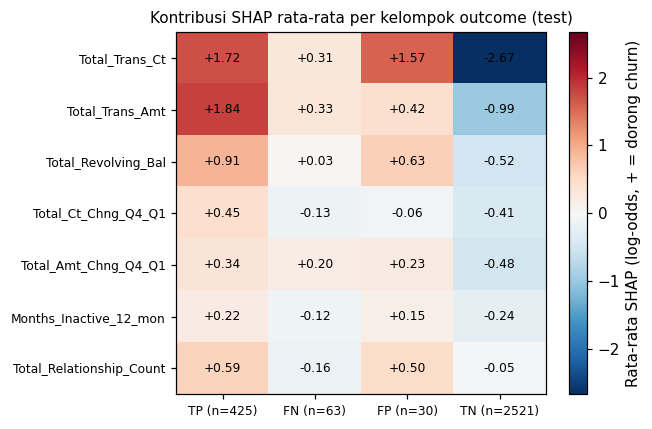

In [ ]:
rows = []
for grp in ["TP", "TN", "FN", "FP"]:
    m = (outcome == grp).to_numpy()
    for f in feature_names:
        rows.append({"Kelompok": grp, "n": int(m.sum()), "Fitur": f, "Mean SHAP": S.loc[m, f].mean(),
                     "Mean |SHAP|": S.loc[m, f].abs().mean(), "Median nilai fitur": D.loc[m, f].median(),
                     "Mean nilai fitur": D.loc[m, f].mean()})
error_shap = pd.DataFrame(rows)
error_shap.to_csv(f"{OUTPUT_DIR}/a4_s7_error_shap.csv", index=False)
print("Mean SHAP per kelompok (fitur utama)")
display(error_shap[error_shap.Fitur.isin(KEY)].pivot(index="Kelompok", columns="Fitur", values="Mean SHAP")[KEY].round(2))
print("Median nilai fitur per kelompok")
display(error_shap[error_shap.Fitur.isin(KEY)].pivot(index="Kelompok", columns="Fitur", values="Median nilai fitur")[KEY].round(2))

p_test = pd.Series(test_prob, index=X_test.index)
diag = []
for grp in ["TP", "TN", "FN", "FP"]:
    m = (outcome == grp).to_numpy()
    diag.append({"Bagian": "Ringkasan kelompok", "Item": grp, "n": int(m.sum()), "Nilai": p_test[m].mean(),
                 "Keterangan": "rata-rata p(churn)"})
fn_p, fp_p = p_test[(outcome == "FN").to_numpy()], p_test[(outcome == "FP").to_numpy()]
for item, n, desc in [("FN p<0,1 (terlewat yakin)", int((fn_p < .1).sum()), "dari FN"),
                      ("FN 0,1<=p<0,3", int(((fn_p >= .1) & (fn_p < .3)).sum()), "dari FN"),
                      ("FN 0,3<=p<0,5 (dekat batas)", int((fn_p >= .3).sum()), "dari FN"),
                      ("FP p>0,9 (salah alarm yakin)", int((fp_p > .9).sum()), "dari FP"),
                      ("FP 0,7<=p<=0,9", int(((fp_p >= .7) & (fp_p <= .9)).sum()), "dari FP"),
                      ("FP 0,5<=p<0,7 (dekat batas)", int((fp_p < .7).sum()), "dari FP")]:
    diag.append({"Bagian": "Tingkat keyakinan", "Item": item, "n": n, "Nilai": np.nan, "Keterangan": desc})
for item, n, desc in [("FN dengan Total_Revolving_Bal = 0", int(((outcome == "FN").to_numpy() & (D.Total_Revolving_Bal == 0)).sum()), "dari 63 FN"),
                      ("FP dengan Total_Revolving_Bal = 0", int(((outcome == "FP").to_numpy() & (D.Total_Revolving_Bal == 0)).sum()), "dari 30 FP"),
                      ("FN dengan Total_Trans_Ct >= 60", int(((outcome == "FN").to_numpy() & (D.Total_Trans_Ct >= 60)).sum()), "dari FN"),
                      ("FP dengan Total_Trans_Ct < 45", int(((outcome == "FP").to_numpy() & (D.Total_Trans_Ct < 45)).sum()), "dari FP")]:
    diag.append({"Bagian": "Profil", "Item": item, "n": n, "Nilai": np.nan, "Keterangan": desc})

for t in (0.2, 0.3, 0.4, 0.5, 0.6):
    pr = (baseline_oof_proba >= t).astype(int)
    diag.append({"Bagian": "Threshold (OOF training)", "Item": f"threshold {t}", "n": int(pr.sum()),
                 "Nilai": f1_score(y_train, pr), "Keterangan": f"precision {precision_score(y_train, pr):.4f}; "
                 f"recall {recall_score(y_train, pr):.4f}; F1 churn (Nilai); Macro F1 {f1_score(y_train, pr, average='macro'):.4f}"})
error_diagnostics = pd.DataFrame(diag)
error_diagnostics.to_csv(f"{OUTPUT_DIR}/a4_s7_error_diagnostics.csv", index=False)
display(error_diagnostics)

heat = error_shap[error_shap.Fitur.isin(KEY)].pivot(index="Fitur", columns="Kelompok", values="Mean SHAP").loc[KEY, ["TP", "FN", "FP", "TN"]]
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(heat.values, cmap="RdBu_r", vmin=-np.abs(heat.values).max(), vmax=np.abs(heat.values).max(), aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels([f"{g} (n={int((outcome == g).sum())})" for g in heat.columns], fontsize=8)
ax.set_yticks(range(len(KEY))); ax.set_yticklabels(KEY, fontsize=8)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:+.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Rata-rata SHAP (log-odds, + = dorong churn)")
ax.set_title("Kontribusi SHAP rata-rata per kelompok outcome (test)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/72_shap_by_outcome.png", dpi=200, bbox_inches="tight"); plt.show()

## 7.3 Segmen Langkah 2 di test set
ambang batas dan model anomali dari training

Error rate keseluruhan test: 0.0306


,n,Churn rate,Error rate,CI 95% bawah,CI 95% atas,Di atas rata-rata (CI),FN,FP,Mean SHAP Total_Revolving_Bal,Mean SHAP Total_Trans_Ct,Mean SHAP Months_on_book,Mean |SHAP| Months_on_book
Segmen,,,,,,,,,,,,
Seluruh test,3039,0.1606,0.0306,0.0250,0.0373,False,63,30,-0.2932,-1.9522,-0.0469,0.1646
Unknown pada >= 1 kolom,916,0.1583,0.0284,0.0194,0.0413,False,15,11,-0.3149,-2.1390,-0.0508,0.1699
Education_Level = Unknown,455,0.1626,0.0374,0.0235,0.0590,False,12,5,-0.3724,-2.1067,-0.0531,0.1707
Income_Category = Unknown,351,0.1595,0.0228,0.0116,0.0443,False,3,5,-0.2411,-2.1222,-0.0376,0.1663
Marital_Status = Unknown,215,0.1395,0.0186,0.0073,0.0469,False,1,3,-0.3129,-2.2486,-0.0683,0.1699
Card_Category = Gold,31,0.0968,0.0323,0.0057,0.1619,False,0,1,-0.4044,-4.5692,-0.0957,0.1437
Card_Category = Platinum,6,0.3333,0.0000,0.0000,0.3903,False,0,0,-0.3683,-2.9398,-0.0765,0.0765
Credit_Limit = batas bawah,166,0.2048,0.0301,0.0129,0.0686,False,1,4,0.7513,-1.8755,-0.0380,0.1756
Credit_Limit = batas atas,149,0.1409,0.0336,0.0144,0.0761,False,4,1,-0.4779,-2.8304,-0.0986,0.1587


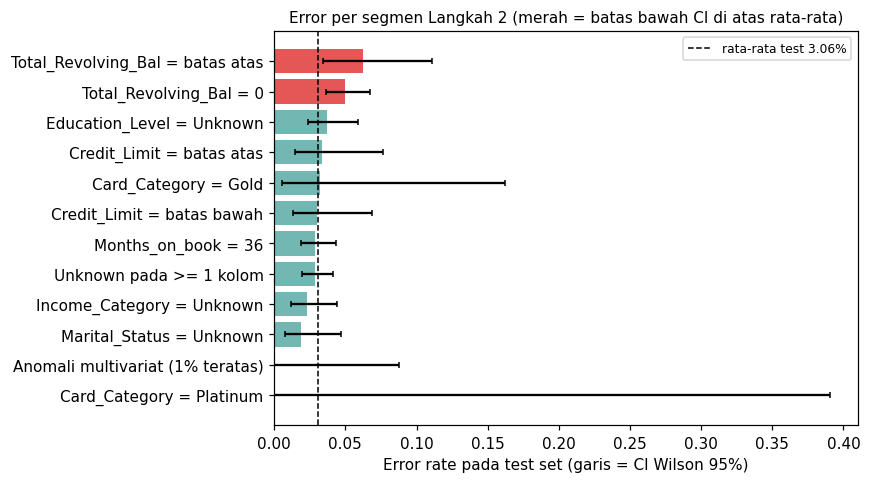

,Bagian,Baris,Kolom,n,Churn rate
0,Total_Revolving_Bal = 0 menurut Total_Trans_Ct,"Ct (0, 40]",-,353,0.703
1,Total_Revolving_Bal = 0 menurut Total_Trans_Ct,"Ct (40, 60]",-,439,0.665
2,Total_Revolving_Bal = 0 menurut Total_Trans_Ct,"Ct (60, 80]",-,584,0.128
3,Total_Revolving_Bal = 0 menurut Total_Trans_Ct,"Ct (80, 140]",-,347,0.037


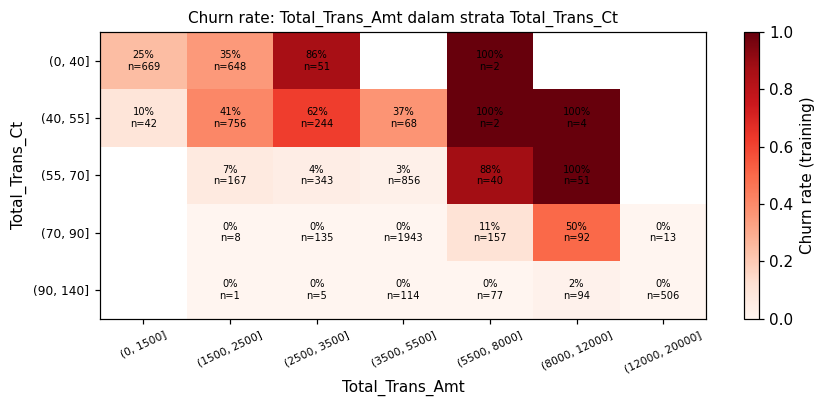

In [ ]:
credit_floor_t, credit_cap_t = X_train["Credit_Limit"].min(), X_train["Credit_Limit"].max()
revolving_cap_t = X_train["Total_Revolving_Bal"].max()
anomaly_test = pd.Series(-iso_forest.score_samples(Z_test), index=X_test.index)
anomaly_cut = anomaly_score.quantile(0.99)
dt = X_test
seg_test = {
    "Seluruh test":                    pd.Series(True, index=dt.index),
    "Unknown pada >= 1 kolom":         (dt[["Education_Level", "Marital_Status", "Income_Category"]] == "Unknown").any(axis=1),
    "Education_Level = Unknown":       dt["Education_Level"] == "Unknown",
    "Income_Category = Unknown":       dt["Income_Category"] == "Unknown",
    "Marital_Status = Unknown":        dt["Marital_Status"] == "Unknown",
    "Card_Category = Gold":            dt["Card_Category"] == "Gold",
    "Card_Category = Platinum":        dt["Card_Category"] == "Platinum",
    "Credit_Limit = batas bawah":      dt["Credit_Limit"] == credit_floor_t,
    "Credit_Limit = batas atas":       dt["Credit_Limit"] == credit_cap_t,
    "Total_Revolving_Bal = 0":         dt["Total_Revolving_Bal"] == 0,
    "Total_Revolving_Bal = batas atas": dt["Total_Revolving_Bal"] == revolving_cap_t,
    "Months_on_book = 36":             dt["Months_on_book"] == 36,
    "Anomali multivariat (1% teratas)": anomaly_test >= anomaly_cut,
}
overall_test_error = float(test_error.mean())
seg_rows = []
for name, m in seg_test.items():
    m = m.to_numpy(); n = int(m.sum()); e = int(test_error[m].sum()); lo, hi = wilson_interval(e, n)
    seg_rows.append({"Segmen": name, "n": n, "Churn rate": float(y_test.to_numpy()[m].mean()),
                     "Error rate": e / n, "CI 95% bawah": lo, "CI 95% atas": hi,
                     "Di atas rata-rata (CI)": bool(lo > overall_test_error),
                     "FN": int((m & (outcome == "FN").to_numpy()).sum()), "FP": int((m & (outcome == "FP").to_numpy()).sum()),
                     "Mean SHAP Total_Revolving_Bal": S.loc[m, "Total_Revolving_Bal"].mean(),
                     "Mean SHAP Total_Trans_Ct": S.loc[m, "Total_Trans_Ct"].mean(),
                     "Mean SHAP Months_on_book": S.loc[m, "Months_on_book"].mean(),
                     "Mean |SHAP| Months_on_book": S.loc[m, "Months_on_book"].abs().mean()})
segment_shap = pd.DataFrame(seg_rows).set_index("Segmen")
segment_shap.to_csv(f"{OUTPUT_DIR}/a4_s7_segment_shap.csv")
print(f"Error rate keseluruhan test: {overall_test_error:.4f}")
display(segment_shap.round(4))

plot_seg = segment_shap.drop(index="Seluruh test").sort_values("Error rate")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(plot_seg.index, plot_seg["Error rate"],
        xerr=[plot_seg["Error rate"] - plot_seg["CI 95% bawah"], plot_seg["CI 95% atas"] - plot_seg["Error rate"]],
        color=["#e45756" if v else "#72b7b2" for v in plot_seg["Di atas rata-rata (CI)"]], capsize=2)
ax.axvline(overall_test_error, color="k", ls="--", lw=1, label=f"rata-rata test {overall_test_error:.2%}")
ax.set_xlabel("Error rate pada test set (garis = CI Wilson 95%)"); ax.legend(fontsize=8)
ax.set_title("Error per segmen Langkah 2 (merah = batas bawah CI di atas rata-rata)", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/73_segment_error.png", dpi=200, bbox_inches="tight"); plt.show()

# Pola data di balik temuan SHAP (training): (a) nilai Total_Revolving_Bal = 0 dan (b) Total_Trans_Amt dalam strata Total_Trans_Ct
tr = X_train.assign(churn=y_train)
patterns = []
b0 = tr[tr.Total_Revolving_Bal == 0]
for interval, g in b0.groupby(pd.cut(b0.Total_Trans_Ct, [0, 40, 60, 80, 140]), observed=True):
    patterns.append({"Bagian": "Total_Revolving_Bal = 0 menurut Total_Trans_Ct", "Baris": f"Ct {interval}", "Kolom": "-", "n": len(g), "Churn rate": g.churn.mean()})
ct_bins, amt_bins = [0, 40, 55, 70, 90, 140], [0, 1500, 2500, 3500, 5500, 8000, 12000, 20000]
tr["ct_bin"], tr["amt_bin"] = pd.cut(tr.Total_Trans_Ct, ct_bins), pd.cut(tr.Total_Trans_Amt, amt_bins)
for (c, a), g in tr.groupby(["ct_bin", "amt_bin"], observed=True):
    patterns.append({"Bagian": "Total_Trans_Amt dalam strata Total_Trans_Ct", "Baris": f"Ct {c}", "Kolom": f"Amt {a}", "n": len(g), "Churn rate": g.churn.mean()})
data_patterns = pd.DataFrame(patterns)
data_patterns.to_csv(f"{OUTPUT_DIR}/a4_s7_data_patterns.csv", index=False)
display(data_patterns[data_patterns.Bagian.str.startswith("Total_Revolving")].round(3))

pv_rate = tr.pivot_table(index="ct_bin", columns="amt_bin", values="churn", aggfunc="mean", observed=False)
pv_n = tr.pivot_table(index="ct_bin", columns="amt_bin", values="churn", aggfunc="count", observed=False)
fig, ax = plt.subplots(figsize=(8, 3.8))
im = ax.imshow(pv_rate.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(pv_rate.shape[1])); ax.set_xticklabels([str(c) for c in pv_rate.columns], fontsize=7, rotation=25)
ax.set_yticks(range(pv_rate.shape[0])); ax.set_yticklabels([str(c) for c in pv_rate.index], fontsize=8)
for i in range(pv_rate.shape[0]):
    for j in range(pv_rate.shape[1]):
        if not np.isnan(pv_rate.values[i, j]):
            ax.text(j, i, f"{pv_rate.values[i, j]:.0%}\nn={int(pv_n.values[i, j])}", ha="center", va="center", fontsize=6.5)
ax.set_xlabel("Total_Trans_Amt"); ax.set_ylabel("Total_Trans_Ct"); plt.colorbar(im, label="Churn rate (training)")
ax.set_title("Churn rate: Total_Trans_Amt dalam strata Total_Trans_Ct", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIGURE_DIR}/74_amt_ct_strata.png", dpi=200, bbox_inches="tight"); plt.show()

## 7.4 Observasi cleanlab
dijelaskan dengan SHAP dari model fold OOF yang tidak melihatnya

In [ ]:
cl_rows = []
for fold in sorted(cv_folds.unique()):
    idx_f = [i for i in flagged.index if cv_folds.loc[i] == fold]
    if not idx_f:
        continue
    fm = clone(final_pipeline).fit(X_train[cv_folds != fold], y_train[cv_folds != fold])
    enc_f, sc_f, xgb_f = (fm.named_steps[k] for k in ("encode", "scale", "model"))
    raw_f = enc_f.transform(X_train.loc[idx_f]); Zf = sc_f.transform(raw_f)
    sv_f = pd.DataFrame(shap.TreeExplainer(xgb_f).shap_values(Zf), index=idx_f, columns=Zf.columns)
    for i in idx_f:
        top = sv_f.loc[i].abs().sort_values(ascending=False).index[:3]
        cl_rows.append({"obs_index": i, "Label asli": int(flagged.at[i, "original_label"]),
                        "Prediksi OOF": int(flagged.at[i, "model_prediction"]), "p(churn) OOF": float(flagged.at[i, "oof_p_churn"]),
                        "Quality score": float(flagged.at[i, "quality_score"]),
                        "Keputusan Langkah 4": cleanlab_review["Decision"].get(i, "tidak direview"),
                        "Total_Revolving_Bal": raw_f.at[i, "Total_Revolving_Bal"], "Total_Trans_Ct": raw_f.at[i, "Total_Trans_Ct"],
                        "SHAP Total_Revolving_Bal": sv_f.at[i, "Total_Revolving_Bal"],
                        "SHAP 5 fitur aktivitas": float(sv_f.loc[i, ACTIVITY].sum()),
                        "SHAP fitur lain": float(sv_f.loc[i].drop(ACTIVITY).sum()),
                        "3 kontributor terbesar": "; ".join(f"{f}={raw_f.at[i, f]:g} ({sv_f.at[i, f]:+.2f})" for f in top)})
cleanlab_shap = pd.DataFrame(cl_rows).set_index("obs_index").loc[flagged.index]
cleanlab_shap.to_csv(f"{OUTPUT_DIR}/a4_s7_cleanlab_shap.csv")
cl_summary = (cleanlab_shap.assign(Pola=lambda t: np.where(t["Label asli"] == 1, "Attrited -> diprediksi Existing", "Existing -> diprediksi Attrited"),
                                   Bal0=lambda t: t["Total_Revolving_Bal"] == 0)
              .groupby("Pola").agg(n=("Label asli", "size"), **{"dengan Bal = 0": ("Bal0", "sum")},
                                   **{"median Total_Trans_Ct": ("Total_Trans_Ct", "median"),
                                      "mean SHAP aktivitas": ("SHAP 5 fitur aktivitas", "mean"),
                                      "mean SHAP fitur lain": ("SHAP fitur lain", "mean"),
                                      "mean SHAP Bal": ("SHAP Total_Revolving_Bal", "mean")}))
display(cl_summary.round(2))

,n,dengan Bal = 0,median Total_Trans_Ct,mean SHAP aktivitas,mean SHAP fitur lain,mean SHAP Bal
Pola,,,,,,
Attrited -> diprediksi Existing,13,0,52.0,-1.71,-1.33,-0.70
Existing -> diprediksi Attrited,19,10,45.0,3.75,1.15,0.38


## 7.5 Tabel temuan

In [ ]:
A = ablation; sg = segment_shap
def f4(x): return f"{x:.4f}"
b0_rows = data_patterns[data_patterns.Bagian.str.startswith("Total_Revolving")]
b0_low = b0_rows[b0_rows.Baris.isin(["Ct (0, 40]", "Ct (40, 60]"])]; b0_high = b0_rows[b0_rows.Baris.isin(["Ct (60, 80]", "Ct (80, 140]"])]
b0_low_rate = (b0_low["Churn rate"] * b0_low.n).sum() / b0_low.n.sum(); b0_high_rate = (b0_high["Churn rate"] * b0_high.n).sum() / b0_high.n.sum()
strata = data_patterns[data_patterns.Bagian.str.startswith("Total_Trans_Amt")]
hi_ticket = strata[(strata.Baris == "Ct (55, 70]") & strata.Kolom.isin(["Amt (5500, 8000]", "Amt (8000, 12000]"])]
hi_ticket_rate = (hi_ticket["Churn rate"] * hi_ticket.n).sum() / hi_ticket.n.sum()
very_high_amt = X_train.Total_Trans_Amt > 12000
cl_exist = cleanlab_shap[cleanlab_shap["Label asli"] == 0]
findings = pd.DataFrame([
 ("Model sangat bergantung pada 5 fitur aktivitas 12 bulan (jumlah/nilai transaksi, perubahan Q4-Q1, bulan tidak aktif)",
  f"Ablation CV: tanpa kelimanya Macro F1 {f4(A.loc[BASE_NAME,'Macro F1 mean'])} -> {f4(A.loc['Tanpa 5 fitur aktivitas 12 bulan','Macro F1 mean'])}, F1 churn {f4(A.loc[BASE_NAME,'F1 (churn) mean'])} -> {f4(A.loc['Tanpa 5 fitur aktivitas 12 bulan','F1 (churn) mean'])}; kontrol Months_on_book {A.loc['Kontrol: tanpa Months_on_book','Δ Macro F1 vs D0']:+.4f} (gambar 71)",
  "fitur",
  "Pertahankan di model; tidak ada bukti kebocoran yang jelas (AUC satu fitur maks. 0,80). Dicatat: fitur ini bisa merupakan akibat churn (bukan tanda dini); tidak dapat dibuktikan karena tidak ada tanggal penutupan rekening"),
 ("Peringkat SHAP tidak sama dengan dampak ablation",
  f"SHAP: Total_Trans_Ct #1; ablation: tanpa Total_Trans_Amt Macro F1 {A.loc['Tanpa Total_Trans_Amt','Δ Macro F1 vs D0']:+.4f} vs tanpa Total_Trans_Ct {A.loc['Tanpa Total_Trans_Ct','Δ Macro F1 vs D0']:+.4f}; keduanya {A.loc['Tanpa Total_Trans_Ct + Total_Trans_Amt','Δ Macro F1 vs D0']:+.4f} (r antar-keduanya 0,81)",
  "fitur / model",
  "Jangan membaca peringkat SHAP sebagai kepentingan tunggal; pasangan fitur berkorelasi dibaca bersama"),
 ("Pola bergelombang Total_Trans_Amt = efek ukuran transaksi rata-rata: pada Total_Trans_Ct yang sama, nilai total lebih tinggi berarti churn lebih tinggi",
  f"Strata Ct (55,70] dengan Amt > 5.500: churn {hi_ticket_rate:.0%} (n={int(hi_ticket.n.sum())}); Amt > 12.000: churn {tr[very_high_amt].churn.mean():.0%} (n={int(very_high_amt.sum())}) (gambar 63, 74)",
  "data",
  "Tidak ada koreksi. Sel kecil hampir deterministik (tampak 'terlalu bersih'): mungkin ciri struktur dataset; tidak dapat diverifikasi. Narasi paper tentang nasabah pindah ke produk berimbal hasil tidak didukung data"),
 ("Segmen Total_Revolving_Bal = 0 tetap berisiko di test set dan mencampur dua perilaku",
  f"Test: error {sg.loc['Total_Revolving_Bal = 0','Error rate']:.2%} (CI bawah {sg.loc['Total_Revolving_Bal = 0','CI 95% bawah']:.2%} > rata-rata {overall_test_error:.2%}), FN {int(sg.loc['Total_Revolving_Bal = 0','FN'])}, FP {int(sg.loc['Total_Revolving_Bal = 0','FP'])}; SHAP Bal rata-rata {sg.loc['Total_Revolving_Bal = 0','Mean SHAP Total_Revolving_Bal']:+.2f}. Training: churn {b0_low_rate:.0%} bila Ct <= 60 vs {b0_high_rate:.0%} bila Ct > 60",
  "fitur",
  "Tidak ada koreksi data. Nilai 0 ambigu (kartu tidak dipakai vs dibayar lunas); butuh fitur tambahan (mis. riwayat pembayaran) bila tersedia"),
 ("Segmen Total_Revolving_Bal di batas atas: error tinggi, nilai kemungkinan terpotong",
  f"Test: error {sg.loc['Total_Revolving_Bal = batas atas','Error rate']:.2%} (n={int(sg.loc['Total_Revolving_Bal = batas atas','n'])}, CI bawah {sg.loc['Total_Revolving_Bal = batas atas','CI 95% bawah']:.2%}); SHAP Bal {sg.loc['Total_Revolving_Bal = batas atas','Mean SHAP Total_Revolving_Bal']:+.2f}",
  "data",
  "Tidak ada koreksi: nilai sebenarnya tidak diketahui. Dicatat sebagai keterbatasan (12 segmen diuji, hasil bersifat indikasi)"),
 ("Lonjakan Months_on_book = 36 tidak memengaruhi model",
  f"Test: error {sg.loc['Months_on_book = 36','Error rate']:.2%} (rata-rata {overall_test_error:.2%}); mean |SHAP| Months_on_book {sg.loc['Months_on_book = 36','Mean |SHAP| Months_on_book']:.2f}; ablation {A.loc['Kontrol: tanpa Months_on_book','Δ Macro F1 vs D0']:+.4f}",
  "data (tanpa dampak)",
  "Tidak ada koreksi"),
 ("FN: profil berada di antara TP dan TN; sebagian besar bukan kesalahan yang yakin",
  f"FN {int((outcome=='FN').sum())}: p<0,1 = {int((fn_p<.1).sum())}, 0,1-0,3 = {int(((fn_p>=.1)&(fn_p<.3)).sum())}, >=0,3 = {int((fn_p>=.3).sum())}; median Total_Trans_Ct FN {D.loc[(outcome=='FN').to_numpy(),'Total_Trans_Ct'].median():.0f} vs TP {D.loc[(outcome=='TP').to_numpy(),'Total_Trans_Ct'].median():.0f} vs TN {D.loc[(outcome=='TN').to_numpy(),'Total_Trans_Ct'].median():.0f}; threshold 0,3-0,5 pada OOF: F1 churn {f1_score(y_train,(baseline_oof_proba>=.3).astype(int)):.4f}-{f1_score(y_train,(baseline_oof_proba>=.5).astype(int)):.4f} (gambar 72)",
  "fitur (utama); label tidak dapat diverifikasi; model (kecil)",
  "Tidak ada koreksi label. Threshold tidak diubah: menurunkannya menukar precision dengan recall tanpa menaikkan F1"),
 ("FP: profil menyerupai churner",
  f"FP {int((outcome=='FP').sum())}: mean p(churn) {fp_p.mean():.2f}; median Total_Trans_Ct {D.loc[(outcome=='FP').to_numpy(),'Total_Trans_Ct'].median():.0f} (TP {D.loc[(outcome=='TP').to_numpy(),'Total_Trans_Ct'].median():.0f}); Bal = 0 pada {int(((outcome=='FP').to_numpy() & (D.Total_Revolving_Bal==0)).sum())} dari {int((outcome=='FP').sum())}",
  "label (status snapshot) atau fitur; tidak dapat dibedakan",
  "Tidak ada koreksi: label Existing hanya status saat data diambil, tanpa sumber independen"),
 ("Observasi cleanlab berlabel Existing yang diprediksi Attrited didorong profil aktivitas dan saldo nol",
  f"{len(cl_exist)} observasi; {int((cl_exist.Total_Revolving_Bal==0).sum())} dengan Bal = 0; mean SHAP 5 fitur aktivitas {cl_exist['SHAP 5 fitur aktivitas'].mean():+.2f} (tabel a4_s7_cleanlab_shap.csv)",
  "label (snapshot) atau fitur",
  "Tetap Unresolved seperti Langkah 4; SHAP bukan bukti independen"),
 ("Koreksi data tambahan dari Langkah 6 dan 7",
  "Tidak ada bukti independen untuk Correct maupun Remove; 0 pelanggaran konsistensi (Langkah 2)",
  "-",
  "ADDITIONAL_CORRECTIONS dan ADDITIONAL_REMOVALS tetap kosong; D2 tidak dijalankan"),
], columns=["Temuan", "Bukti", "Sumber", "Tindakan"])
findings.to_csv(f"{OUTPUT_DIR}/a4_s7_findings.csv", index=False)
pd.set_option("display.max_colwidth", None)
display(findings)

,Temuan,Bukti,Sumber,Tindakan
0,"Model sangat bergantung pada 5 fitur aktivitas 12 bulan (jumlah/nilai transaksi, perubahan Q4-Q1, bulan tidak aktif)","Ablation CV: tanpa kelimanya Macro F1 0.9464 -> 0.6894, F1 churn 0.9096 -> 0.4574; kontrol Months_on_book +0.0017 (gambar 71)",fitur,"Pertahankan di model; tidak ada bukti kebocoran yang jelas (AUC satu fitur maks. 0,80). Dicatat: fitur ini bisa merupakan akibat churn (bukan tanda dini); tidak dapat dibuktikan karena tidak ada tanggal penutupan rekening"
1,Peringkat SHAP tidak sama dengan dampak ablation,"SHAP: Total_Trans_Ct #1; ablation: tanpa Total_Trans_Amt Macro F1 -0.0535 vs tanpa Total_Trans_Ct -0.0142; keduanya -0.1229 (r antar-keduanya 0,81)",fitur / model,Jangan membaca peringkat SHAP sebagai kepentingan tunggal; pasangan fitur berkorelasi dibaca bersama
2,"Pola bergelombang Total_Trans_Amt = efek ukuran transaksi rata-rata: pada Total_Trans_Ct yang sama, nilai total lebih tinggi berarti churn lebih tinggi","Strata Ct (55,70] dengan Amt > 5.500: churn 95% (n=91); Amt > 12.000: churn 0% (n=519) (gambar 63, 74)",data,Tidak ada koreksi. Sel kecil hampir deterministik (tampak 'terlalu bersih'): mungkin ciri struktur dataset; tidak dapat diverifikasi. Narasi paper tentang nasabah pindah ke produk berimbal hasil tidak didukung data
3,Segmen Total_Revolving_Bal = 0 tetap berisiko di test set dan mencampur dua perilaku,"Test: error 4.95% (CI bawah 3.61% > rata-rata 3.06%), FN 23, FP 14; SHAP Bal rata-rata +1.31. Training: churn 68% bila Ct <= 60 vs 9% bila Ct > 60",fitur,Tidak ada koreksi data. Nilai 0 ambigu (kartu tidak dipakai vs dibayar lunas); butuh fitur tambahan (mis. riwayat pembayaran) bila tersedia
4,"Segmen Total_Revolving_Bal di batas atas: error tinggi, nilai kemungkinan terpotong","Test: error 6.25% (n=160, CI bawah 3.43%); SHAP Bal +0.91",data,"Tidak ada koreksi: nilai sebenarnya tidak diketahui. Dicatat sebagai keterbatasan (12 segmen diuji, hasil bersifat indikasi)"
5,Lonjakan Months_on_book = 36 tidak memengaruhi model,Test: error 2.86% (rata-rata 3.06%); mean |SHAP| Months_on_book 0.15; ablation +0.0017,data (tanpa dampak),Tidak ada koreksi
6,FN: profil berada di antara TP dan TN; sebagian besar bukan kesalahan yang yakin,"FN 63: p<0,1 = 16, 0,1-0,3 = 26, >=0,3 = 21; median Total_Trans_Ct FN 51 vs TP 43 vs TN 70; threshold 0,3-0,5 pada OOF: F1 churn 0.9092-0.9097 (gambar 72)",fitur (utama); label tidak dapat diverifikasi; model (kecil),Tidak ada koreksi label. Threshold tidak diubah: menurunkannya menukar precision dengan recall tanpa menaikkan F1
7,FP: profil menyerupai churner,FP 30: mean p(churn) 0.78; median Total_Trans_Ct 41 (TP 43); Bal = 0 pada 14 dari 30,label (status snapshot) atau fitur; tidak dapat dibedakan,"Tidak ada koreksi: label Existing hanya status saat data diambil, tanpa sumber independen"
8,Observasi cleanlab berlabel Existing yang diprediksi Attrited didorong profil aktivitas dan saldo nol,19 observasi; 10 dengan Bal = 0; mean SHAP 5 fitur aktivitas +3.75 (tabel a4_s7_cleanlab_shap.csv),label (snapshot) atau fitur,Tetap Unresolved seperti Langkah 4; SHAP bukan bukti independen
9,Koreksi data tambahan dari Langkah 6 dan 7,Tidak ada bukti independen untuk Correct maupun Remove; 0 pelanggaran konsistensi (Langkah 2),-,ADDITIONAL_CORRECTIONS dan ADDITIONAL_REMOVALS tetap kosong; D2 tidak dijalankan


# 8. Evaluate the Final Dataset and Model

## 8.1 Latih ulang model final dan evaluasi di test set (sekali)

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
X_fit, y_fit = (X_train, y_train) if final_modify_train is None else final_modify_train(X_train, y_train)
final_model, final_test_metrics, final_test_pred, final_test_prob = evaluate_on_test(
    final_pipeline, X_fit, y_fit, X_test, y_test)
# Pembanding "tidak dipilih": kandidat D1 terbaik di CV (informatif, bukan dasar keputusan)
alt_name = SELECTED_D1
alt_model, alt_metrics, alt_pred, alt_prob = evaluate_on_test(
    IMBALANCE_CANDIDATES[alt_name], X_train, y_train, X_test, y_test)

final_test_comparison = pd.DataFrame(
    [baseline_test_metrics, final_test_metrics],
    index=["Baseline A3", f"Final ({FINAL_EXPERIMENT[:2]})"])[METRIC_ORDER]
final_test_comparison.loc["Selisih (final - baseline)"] = final_test_comparison.iloc[1] - final_test_comparison.iloc[0]
final_test_comparison.loc[f"{alt_name} (tidak dipilih)"] = pd.Series(alt_metrics)[METRIC_ORDER]
final_test_comparison.loc["Selisih (D1 tidak dipilih - baseline)"] = final_test_comparison.iloc[3] - final_test_comparison.iloc[0]
final_test_comparison.to_csv(f"{OUTPUT_DIR}/a4_s8_test_comparison.csv")
display(final_test_comparison.round(4))

,Macro F1,F1 (churn),Precision (churn),Recall (churn),PR-AUC,ROC-AUC,Balanced Accuracy,Accuracy
Baseline A3,0.9416,0.9014,0.9341,0.8709,0.9648,0.9928,0.9296,0.9694
Final (D0),0.9416,0.9014,0.9341,0.8709,0.9648,0.9928,0.9296,0.9694
Selisih (final - baseline),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
D1b SMOTE (tidak dipilih),0.9406,0.8997,0.9281,0.8730,0.9650,0.9928,0.9300,0.9687
Selisih (D1 tidak dipilih - baseline),-0.0010,-0.0017,-0.0060,0.0020,0.0003,-0.0001,0.0004,-0.0007


## 8.2 Confusion matrix berdampingan

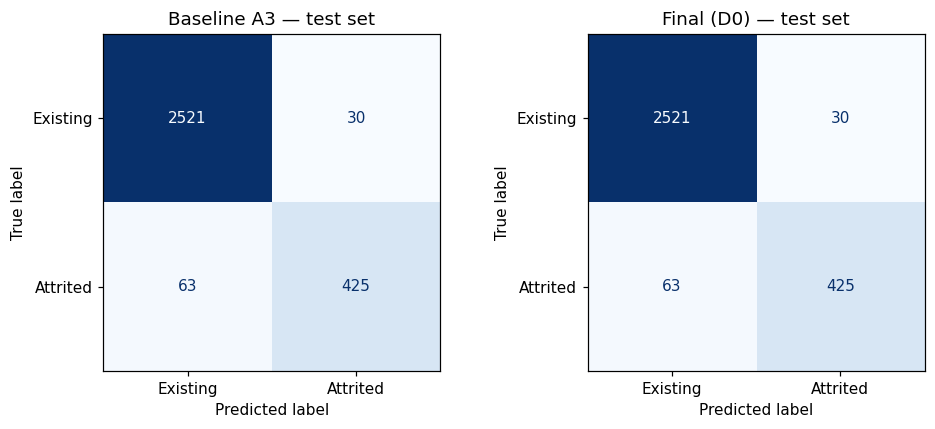

,Baseline A3,Final,Selisih
FN (churn terlewat),63,63,0
FP (salah alarm),30,30,0
TP,425,425,0
TN,2521,2521,0


In [ ]:
cm_base, cm_final = (confusion_matrix(y_test, p) for p in (baseline_test_pred, final_test_pred))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, pred, title in zip(axes, (baseline_test_pred, final_test_pred),
                           ("Baseline A3", f"Final ({FINAL_EXPERIMENT[:2]})")):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Existing", "Attrited"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{title} — test set")
plt.tight_layout()
plt.savefig(f"{FIGURE_DIR}/81_confusion_matrix_baseline_vs_final.png", bbox_inches="tight", dpi=200)
plt.show()

cm_table = pd.DataFrame({"Baseline A3": [cm_base[1, 0], cm_base[0, 1], cm_base[1, 1], cm_base[0, 0]],
                         "Final":       [cm_final[1, 0], cm_final[0, 1], cm_final[1, 1], cm_final[0, 0]]},
                        index=["FN (churn terlewat)", "FP (salah alarm)", "TP", "TN"])
cm_table["Selisih"] = cm_table["Final"] - cm_table["Baseline A3"]
display(cm_table)

## 8.3 Uji McNemar (exact) pada prediksi test

In [ ]:
def mcnemar_test(pred_a, pred_b, y_true):
    a_ok, b_ok = (np.asarray(pred_a) == y_true.to_numpy()), (np.asarray(pred_b) == y_true.to_numpy())
    n01, n10 = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    p = 1.0 if n01 + n10 == 0 else float(mcnemar(
        [[int((a_ok & b_ok).sum()), n01], [n10, int((~a_ok & ~b_ok).sum())]], exact=True).pvalue)
    return {"Hanya baseline benar": n01, "Hanya model pembanding benar": n10, "p-value (McNemar exact)": p}

mcnemar_table = pd.DataFrame({
    "Final vs Baseline A3":       mcnemar_test(baseline_test_pred, final_test_pred, y_test),
    f"{alt_name} vs Baseline A3": mcnemar_test(baseline_test_pred, alt_pred, y_test)}).T
mcnemar_table.to_csv(f"{OUTPUT_DIR}/a4_s8_mcnemar.csv")
display(mcnemar_table)

,Hanya baseline benar,Hanya model pembanding benar,p-value (McNemar exact)
Final vs Baseline A3,0.0,0.0,1.000000
D1b SMOTE vs Baseline A3,16.0,14.0,0.855536


## 8.4 Konsistensi CV (Langkah 5) vs test set

In [ ]:
cv_vs_test = pd.DataFrame({
    "Δ Macro F1 CV vs D0": [vs_d0.loc[alt_name, "Δ mean Macro F1 vs D0"]],
    "Fold unggul (CV)":    [int(vs_d0.loc[alt_name, "Fold unggul"])],
    "Lolos aturan CV":     [bool(vs_d0.loc[alt_name, "Lolos aturan"])],
    "Δ Macro F1 test vs baseline": [final_test_comparison.loc["Selisih (D1 tidak dipilih - baseline)", "Macro F1"]],
}, index=[alt_name])
display(cv_vs_test.round(4))
cv_vs_test.to_csv(f"{OUTPUT_DIR}/a4_s8_cv_vs_test.csv")

assert FINAL_EXPERIMENT != D0_LABEL or np.allclose(final_test_comparison.iloc[2].values.astype(float), 0), \
    "FINAL_EXPERIMENT = D0 tetapi hasil test berbeda dari baseline"

,Δ Macro F1 CV vs D0,Fold unggul (CV),Lolos aturan CV,Δ Macro F1 test vs baseline
D1b SMOTE,0.0014,2,False,-0.001
